# Week 6 — slide notebook (NO₂ forecasting, random-week split)
**one section = one slide**. Each section makes the figure for that slide (saved in `figures_slides/`), and the notes are what I say.

- The question I'm answering: **at hour *t*, using only what is known at *t*, predict NO₂ at each sensor 1, 2 and 3 hours ahead (*t+1, t+2, t+3*).**
- Data: `data/master_model/master_model.parquet` (I never edit it).
- Running the whole notebook takes about 10 minutes.

## Setup (not a slide) — run this first
- Imports, plot style, and one colour per model so each model keeps its colour on every slide (grey = persistence, blue = linear, green = GAM, orange = GBM).
- `shift_within_sensor` is the helper I use for every lag and target: it takes the value *k* hours earlier or later for the **same** sensor, and gives NaN at sensor borders.

In [37]:
# %pip install pandas pyarrow numpy matplotlib scikit-learn
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import SplineTransformer

pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "0.9", "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "font.size": 11, "axes.titlesize": 12, "axes.titleweight": "bold"})

DATA = "master_model.parquet"     # this notebook lives in code/week 6/
FIGS = "figures_slides"; os.makedirs(FIGS, exist_ok=True)
HORIZONS = [1, 2, 3]
SEED = 0

# one colour per model / baseline, used on every slide
COL = {"Persistence": "#8c8c87", "Climatology": "#eda100", "Same hour yesterday": "#e87ba4",
       "Same hour last week": "#008300", "Linear": "#2a78d6", "GAM": "#1baf7a", "GBM": "#eb6834"}
def colour(name):
    return COL.get(name, COL.get(name.split(" (")[0], "0.5"))
def save(name):
    plt.tight_layout(); plt.savefig(f"{FIGS}/{name}.png", dpi=200, bbox_inches="tight"); plt.show()

def shift_within_sensor(x, k):
    """Value k rows earlier (k > 0) or later (k < 0) for the SAME sensor; NaN across sensor borders."""
    x = np.asarray(x, dtype=np.float64); out = np.full(len(x), np.nan)
    if k > 0:
        out[k:] = np.where(SID[k:] == SID[:-k], x[:-k], np.nan)
    elif k < 0:
        k = -k; out[:-k] = np.where(SID[:-k] == SID[k:], x[k:], np.nan)
    else:
        out[:] = x
    return out

---
# Slide 0 — Opening
**On the slide:** title, team names, one-line question.

**What I say**
- "We forecast NO₂ at Chicago's ~270 Open Air sensors **1, 2 and 3 hours ahead**."
- Why it matters: an early warning before NO₂ peaks (morning rush), plus a base for the tree-planting work.
- "Last week the professor asked us to: (1) not judge models by R² alone, (2) pick lags with ACF/PACF, (3) test features one group at a time instead of stacking them. This week does all three."
- One-sentence result: "Our best model beats 'NO₂ stays the same' by about **5% at 1 hour and 12% at 3 hours** on test weeks it never saw."

(No code for this slide.)

---
# Slide 1 — Data set-up and the random-week split
**On the slide:** the week-strip figure (`s1_split_weeks.png`) + 5 bullets.

**What I say**
- **Data:** 2.5 million rows. One row = one sensor in one hour. 269 sensors, 31 Aug 2025 → 26 Sep 2026.
- Each row has: NO₂, past NO₂ (lags), time of day/week, O'Hare weather, citywide average NO₂, and land use around the sensor.
- **How I split the data:** whole **weeks** (Monday–Sunday) are randomly put into **train 70% / validation 15% / test 15%**.
  - I shuffle **within each season**, so every split has fall, winter, spring and summer weeks (2 val + 2 test weeks per season).
  - Why: in our first try, training was Sep–Apr only, so the model **never saw summer** and was tested on summer. Weather looked useless for that reason.
- **Why whole weeks, not random hours:** neighbouring hours are almost the same (correlation 0.9). If 9 am were in training and 10 am in test, the model would basically see the answer.
- **All sensors in a week go to the same split:** all sensors share the same weather and the same citywide NO₂ at a given hour, so splitting by sensor would also leak.
- **Removed:**
  - **Smoke weeks, 13 Jul – 2 Aug 2026:** a Canadian wildfire smoke episode on 16–20 Jul (the PM2.5 spike in the top panel) plus the week after it, for cleaner data.
  - **First 2 weeks:** the "same hour last week" lag doesn't exist yet there.
  - **A 1-day gap** at the start of any week whose neighbour is in a different split, so the end of a train week can't leak into the start of a test week.
- **Order matters:** I built lags and targets on the full, unbroken timeline **first**, then dropped rows. Lags may look back into another split; that's the past, which is known at forecast time.
- Rows used per horizon: ~1.49M train, ~0.30M val, ~0.30M test. A row is used only if NO₂ now, every candidate lag (up to 26 h back, plus last week) and every feature exist, so every model is scored on exactly the same rows.


In [38]:
COLS = ["sensor_id", "ts_utc", "ts_local", "lat", "lon", "no2", "no2_lag1", "no2_t3",
        "hour", "dow", "is_holiday", "no2_city", "log_pm25_city",
        "temp", "rhum", "wspd_ms", "wind_u", "wind_v", "is_calm",
        "canopy_pct", "impervious_pct", "dist_downtown_m", "road_len_expwy_500", "industrial_m2_500"]
m = pd.read_parquet(DATA, columns=COLS).sort_values(["sensor_id", "ts_utc"]).reset_index(drop=True)
SID  = m["sensor_id"].astype("category").cat.codes.to_numpy().astype(np.int64)
HOUR = m["hour"].to_numpy().astype(np.int64)
NO2  = m["no2"].to_numpy(dtype=np.float64)

# check: every sensor has a complete hourly calendar, so "one row back" = "one hour back"
assert (m.groupby(SID)["ts_utc"].diff().dropna() == pd.Timedelta(hours=1)).all()
assert np.allclose(shift_within_sensor(NO2, 1), m["no2_lag1"], equal_nan=True)
assert np.allclose(shift_within_sensor(NO2, -3), m["no2_t3"], equal_nan=True)
m = m.drop(columns=["no2_lag1", "no2_t3"])
print(f"rows {len(m):,} | sensors {m.sensor_id.nunique()} | {m.ts_local.min():%Y-%m-%d} -> {m.ts_local.max():%Y-%m-%d}")

rows 2,512,408 | sensors 269 | 2025-08-31 -> 2026-09-26


In [39]:
# ---- weeks, seasons, excluded weeks
SMOKE_START, SMOKE_END = pd.Timestamp("2026-07-13"), pd.Timestamp("2026-08-02")   # Mon ... Sun
LOCAL = m["ts_local"].dt.tz_localize(None)
WEEK_START = LOCAL.dt.normalize() - pd.to_timedelta(m["dow"], unit="D")          # dow 0 = Monday
FIRST_DAY = ((LOCAL - WEEK_START) < pd.Timedelta(hours=24)).to_numpy()
BLOCK = pd.factorize(WEEK_START, sort=True)[0]                                    # week id (bootstrap blocks)
SEASON = {12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
          6: "summer", 7: "summer", 8: "summer", 9: "fall", 10: "fall", 11: "fall"}
weeks = pd.DataFrame({"week": np.sort(WEEK_START.unique())})
weeks["season"] = (weeks["week"] + pd.Timedelta(days=3)).dt.month.map(SEASON)
weeks["status"] = "use"
weeks.loc[weeks.index[:2], "status"] = "warm-up"
weeks.loc[(weeks["week"] >= SMOKE_START) & (weeks["week"] <= SMOKE_END), "status"] = "excluded"

def make_split(seed):
    """Row label: train / val / test / gap / warm-up / excluded. Weeks shuffled within season, 70/15/15."""
    r = np.random.default_rng(seed)
    lab = weeks["status"].where(weeks["status"] != "use", "")
    for _, g in weeks[weeks["status"] == "use"].groupby("season"):
        ix = r.permutation(g.index.to_numpy())
        n = max(1, round(0.15 * len(ix)))
        lab[ix[:n]] = "test"; lab[ix[n:2 * n]] = "val"; lab[ix[2 * n:]] = "train"
    row_lab  = WEEK_START.map(dict(zip(weeks["week"], lab))).to_numpy()
    row_prev = WEEK_START.map(dict(zip(weeks["week"], lab.shift(1).fillna("none")))).to_numpy()
    gap = FIRST_DAY & (row_prev != row_lab) & np.isin(row_lab, ["train", "val", "test"])
    return np.where(gap, "gap", row_lab).astype(object), lab

SPLIT, weeks["split"] = make_split(SEED)
display(pd.crosstab(weeks["season"], weeks["split"]).loc[["fall", "winter", "spring", "summer"]])
print(pd.Series(SPLIT).value_counts().to_string())

split,excluded,test,train,val,warm-up
season,,,,,
fall,0,2,12,2,1
winter,0,2,9,2,0
spring,0,2,9,2,0
summer,3,2,6,2,1


train       1540847
val          315086
test         314856
gap          160656
excluded     134945
warm-up       46018


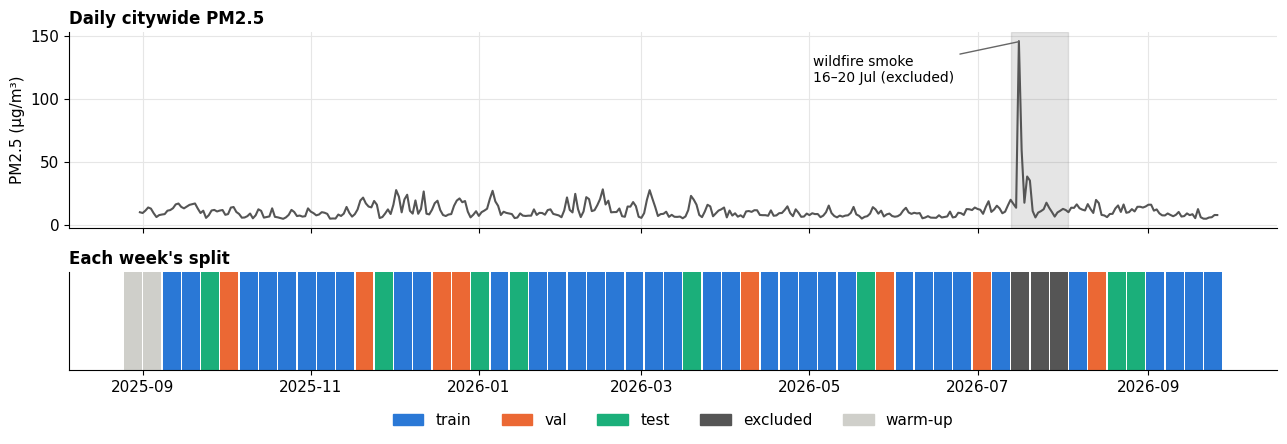

In [40]:
day_pm = np.exp(m.groupby(LOCAL.dt.normalize())["log_pm25_city"].mean())
SPLIT_COL = {"train": "#2a78d6", "val": "#eb6834", "test": "#1baf7a", "excluded": "#555555", "warm-up": "#cfcfca"}
fig, ax = plt.subplots(2, 1, figsize=(13, 4.6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax[0].plot(day_pm.index, day_pm.values, lw=1.5, c="#555555")
ax[0].axvspan(SMOKE_START, SMOKE_END + pd.Timedelta(days=1), color="#555555", alpha=0.15)
ax[0].annotate("wildfire smoke\n16–20 Jul (excluded)", (pd.Timestamp("2026-07-17"), day_pm.max()),
               xytext=(-150, -10), textcoords="offset points", fontsize=10, va="top",
               arrowprops=dict(arrowstyle="-", color="0.4"))
ax[0].set_ylabel("PM2.5 (µg/m³)"); ax[0].set_title("Daily citywide PM2.5", loc="left")
for _, w in weeks.iterrows():
    ax[1].axvspan(w["week"] + pd.Timedelta(hours=6), w["week"] + pd.Timedelta(days=7) - pd.Timedelta(hours=6),
                  color=SPLIT_COL[w["split"]], lw=0)
ax[1].set_yticks([]); ax[1].grid(False); ax[1].set_title("Each week's split", loc="left")
ax[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in SPLIT_COL.values()], labels=list(SPLIT_COL),
             ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.3), frameon=False)
save("s1_split_weeks")

In [41]:
# ---- targets and lags: built on the FULL continuous table first, then rows are filtered
CODE = {"train": 0, "val": 1, "test": 2}
def build_targets(split):
    """y_h = NO2 at t+h; dropped if hour t+h has a different label than hour t (other split / gap / excluded)."""
    sc = pd.Series(split).map(CODE).to_numpy(dtype=np.float64)
    for h in HORIZONS:
        y = shift_within_sensor(NO2, -h)
        y[~(shift_within_sensor(sc, -h) == sc)] = np.nan
        m[f"y{h}"] = y.astype(np.float32)
build_targets(SPLIT)

def lag_col(k):
    """Column with NO2 k hours before t (k = 0 is NO2 at t); created the first time it is asked for."""
    if k == 0:
        return "no2"
    if f"L{k}" not in m.columns:
        m[f"L{k}"] = shift_within_sensor(NO2, k).astype(np.float32)
    return f"L{k}"

m["hour_sin"] = np.sin(2 * np.pi * m["hour"] / 24).astype(np.float32)
m["hour_cos"] = np.cos(2 * np.pi * m["hour"] / 24).astype(np.float32)
m["dow_sin"]  = np.sin(2 * np.pi * m["dow"] / 7).astype(np.float32)
m["dow_cos"]  = np.cos(2 * np.pi * m["dow"] / 7).astype(np.float32)
m["weekend"]  = (m["dow"] >= 5).astype(np.float32)
m["is_holiday"] = m["is_holiday"].astype(np.float32); m["is_calm"] = m["is_calm"].astype(np.float32)

GROUPS = {"time":    ["hour_sin", "hour_cos", "dow_sin", "dow_cos", "is_holiday"],
          "weather": ["temp", "rhum", "wspd_ms", "wind_u", "wind_v", "is_calm"],
          "city":    ["no2_city"],
          "geo":     ["canopy_pct", "impervious_pct", "dist_downtown_m", "road_len_expwy_500", "industrial_m2_500"]}
ALL_GROUP_COLS = [c for g in GROUPS.values() for c in g]

def make_rows(split):
    """Row indices per split: target, every candidate lag and every feature must exist -> same rows for every model."""
    out = {}
    for h in HORIZONS:
        need = [f"y{h}"] + [lag_col(k) for k in range(27)] + [lag_col(168 - h)] + ALL_GROUP_COLS   # every candidate lag
        ok = m[need].notna().all(axis=1).to_numpy()
        out[h] = {s: np.flatnonzero(ok & (split == s)) for s in ["train", "val", "test"]}
    return out
ROWS = make_rows(SPLIT)
for h in HORIZONS:
    print(f"t+{h}: " + "  ".join(f"{s} {len(ix):,}" for s, ix in ROWS[h].items()))

t+1: train 1,485,373  val 298,573  test 306,296
t+2: train 1,482,563  val 296,797  test 304,459
t+3: train 1,479,763  val 295,030  test 302,632


---
# Slide 2 — How I score the forecasts

- "MAE is my headline because it's in ppb and easy to read: 'on average we miss by 2.3 ppb'."
- "I don't lead with R²: NO₂ one hour from now is so close to NO₂ now that even doing nothing gets R² = 0.85 at t+1. A high R² mostly says the lags work."
- "**Skill %** answers the real question: do we beat the simplest honest forecast? 10% skill = our errors are 10% smaller than 'same as now'."
- Worked example (from the code): actual 10, 12, 20; my forecast 11, 12, 17 → misses 1, 0, 3 → **MAE 1.33**. Persistence (8, 10, 12) misses 2, 2, 8 → MAE 4 → **skill 67%**. Bias −0.67 (I under-predicted the 20).
- **Uncertainty:** every comparison has a 95% interval from a **week-block bootstrap**: I resample whole weeks 1,000 times and see how much the difference moves. `*` = the interval doesn't include 0, so the difference is real, not luck.

In [42]:
def scores(y, p, persist):
    y, p, persist = (np.asarray(a, dtype=np.float64) for a in (y, p, persist))
    e = p - y
    mae = np.abs(e).mean()
    return {"MAE": mae, "RMSE": np.sqrt((e ** 2).mean()), "Bias": e.mean(),
            "R2": 1 - (e ** 2).sum() / ((y - y.mean()) ** 2).sum(),
            "Skill%": 100 * (1 - mae / np.abs(persist - y).mean())}

def delta_mae_ci(y, p_ref, p_new, block, B=1000, seed=SEED):
    """MAE(new) - MAE(ref) with a 95% week-block bootstrap CI (whole weeks resampled). Negative = new is better."""
    d = np.abs(np.asarray(p_new, float) - y) - np.abs(np.asarray(p_ref, float) - y)
    s, c = np.bincount(block, weights=d), np.bincount(block).astype(float)
    s, c = s[c > 0], c[c > 0]
    idx = np.random.default_rng(seed).integers(0, len(s), (B, len(s)))
    boot = s[idx].sum(1) / c[idx].sum(1)
    return d.mean(), np.percentile(boot, 2.5), np.percentile(boot, 97.5)

def fmt_ci(t):
    est, lo, hi = t
    return f"{est:+.3f} [{lo:+.3f}, {hi:+.3f}]" + ("*" if (lo > 0 or hi < 0) else "")

# tiny worked example for the slide
y_ex = np.array([10, 12, 20]); p_ex = np.array([11, 12, 17]); pers_ex = np.array([8, 10, 12])
pd.DataFrame([scores(y_ex, p_ex, pers_ex)], index=["example: actual 10,12,20 | forecast 11,12,17 | persistence 8,10,12"])

,MAE,RMSE,Bias,R2,Skill%
"example: actual 10,12,20 | forecast 11,12,17 | persistence 8,10,12",1.333,1.826,-0.667,0.821,66.667


---
# Slide 3 — Baselines
**On the slide:** the bar chart (`s3_baselines.png`).

- **Persistence:** NO₂ at *t+h* = NO₂ now.
- **Climatology:** the usual NO₂ for this sensor at this hour of day (average over training weeks).
- **Same hour yesterday:** NO₂ 24 hours before the target hour.
- **Same hour last week:** NO₂ 168 hours (7 days) before the target hour.


- "Persistence is by far the best: MAE **1.69 / 2.50 / 3.06 ppb** at t+1 / t+2 / t+3. This is the bar every model must beat."
- "Its error **grows with the horizon**: the further ahead, the more NO₂ has changed. That's where a model can help most."
- "Climatology (~3.75 ppb) is flat across horizons and much worse at short range → **NO₂ right now matters more than the usual daily pattern**."
- "Yesterday (~4.5) and last week (~4.8) alone are the worst. Days differ a lot (weather, traffic), so they're weak alone, but they still help **in combination** with current NO₂ (next slides)."


MAE  RMSE   Bias     R2   Skill%
horizon baseline                                              
t+1     Persistence         1.691 2.522  0.024  0.792    0.000
        Climatology         3.760 4.953  0.161  0.197 -122.376
        Same hour yesterday 4.483 6.168  0.445 -0.246 -165.162
        Same hour last week 4.780 6.570 -0.569 -0.413 -182.712
t+2     Persistence         2.501 3.675  0.047  0.555    0.000
        Climatology         3.745 4.932  0.170  0.198  -49.776
        Same hour yesterday 4.472 6.152  0.454 -0.248  -78.830
        Same hour last week 4.774 6.564 -0.555 -0.421  -90.902
t+3     Persistence         3.063 4.425  0.066  0.350    0.000
        Climatology         3.732 4.913  0.179  0.199  -21.838
        Same hour yesterday 4.463 6.142  0.463 -0.252  -45.683
        Same hour last week 4.767 6.557 -0.539 -0.427  -55.633

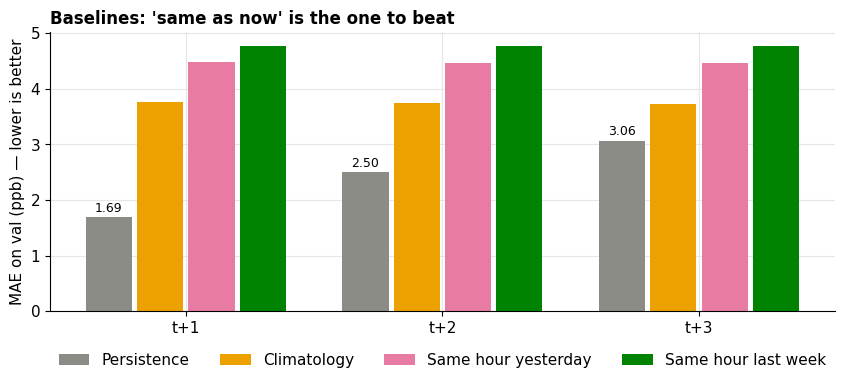

In [43]:
def X(cols, idx):
    return np.column_stack([m[c].to_numpy()[idx] for c in cols]).astype(np.float64)
def Y(h, idx):
    return m[f"y{h}"].to_numpy()[idx].astype(np.float64)

def climatology(h, fit_idx):
    """Mean of y_h for each (sensor, hour of day), from the fitting rows only."""
    key = SID * 24 + HOUR; y = m[f"y{h}"].to_numpy().astype(np.float64); n = key.max() + 1
    s = np.bincount(key[fit_idx], weights=y[fit_idx], minlength=n); c = np.bincount(key[fit_idx], minlength=n)
    out = np.where(c > 0, s / np.maximum(c, 1), np.nan)[key]
    hour_mean = np.bincount(HOUR[fit_idx], weights=y[fit_idx], minlength=24) / np.bincount(HOUR[fit_idx], minlength=24)
    return np.where(np.isnan(out), hour_mean[HOUR], out)

def baseline_preds(h, idx, clim):
    return {"Persistence": NO2[idx],
            "Climatology": clim[idx],
            "Same hour yesterday": m[lag_col(24 - h)].to_numpy()[idx].astype(np.float64),
            "Same hour last week": m[lag_col(168 - h)].to_numpy()[idx].astype(np.float64)}

CLIM = {h: climatology(h, ROWS[h]["train"]) for h in HORIZONS}
rows = []
for h in HORIZONS:
    va = ROWS[h]["val"]; y = Y(h, va)
    for name, p in baseline_preds(h, va, CLIM[h]).items():
        rows.append({"horizon": f"t+{h}", "baseline": name, **scores(y, p, NO2[va])})
base_tbl = pd.DataFrame(rows).set_index(["horizon", "baseline"])
display(base_tbl)

mae = base_tbl["MAE"].unstack("baseline")[list(baseline_preds(1, ROWS[1]["val"][:1], CLIM[1]))]
fig, ax = plt.subplots(figsize=(9, 4))
w = 0.2
for i, b in enumerate(mae.columns):
    bars = ax.bar(np.arange(3) + (i - 1.5) * w, mae[b], w - 0.02, color=colour(b), label=b)
    if b == "Persistence":
        ax.bar_label(bars, fmt="%.2f", fontsize=9, padding=2)
ax.set_xticks(range(3), mae.index); ax.set_ylabel("MAE on val (ppb) — lower is better")
ax.set_title("Baselines: 'same as now' is the one to beat", loc="left")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False)
save("s3_baselines")

---
# Slide 4 — Choosing lags with ACF and PACF
**On the slide:** the 2×2 ACF/PACF figure (`s4_acf_pacf.png`). Left = raw NO₂, right = NO₂ minus its usual value at that hour.

**What the two plots mean**
- **ACF (autocorrelation):** how similar NO₂ now is to NO₂ *k* hours ago. It includes **indirect** links (3 h ago looks related partly because it's related to 2 h ago, which is related to 1 h ago).
- **PACF (partial autocorrelation):** the same question, but only what lag *k* adds **after** the shorter lags are already known. This is what I use to pick lags.
- My analogy: ACF = "does grandpa's height predict yours?" (yes, through your parents). PACF = "does grandpa add anything once I know your parents?" (barely).

**Raw vs "minus usual value"**
- **Raw:** the NO₂ values as measured.
- **Minus usual value:** from each value I subtract **that sensor's average NO₂ at that hour of day** (24 averages per sensor, from training weeks). What's left is "how unusual NO₂ is right now".
- Why both: if a lag only matters in the raw plot, its information is the **daily rhythm** (rush hours repeat every day).

* *
- "ACF: very strong short memory (0.90 at 1 h, 0.67 at 3 h) and bumps **every 24 hours** (daily cycle), plus a bump at 168 h (same hour last week)."
- "PACF, raw: only lags **1, 2** and the band **19–26 hours** add new information. Lags 3, 6 and 12, which we used last week, add nothing."
- "PACF after removing the usual value: only **lags 1 and 2** remain → the 24-hour band is the daily rhythm."
- "With 1.5M rows everything is 'statistically significant', so I only count |PACF| > 0.05 as meaningful (the grey band)."

**Lags I take from this** (counted back from *t*)
- **PACF lags:** every lag with |PACF raw| > 0.05 → **1, 2, 19, 20, 21, 22, 25, 26**, plus NO₂ now (lag 0).
- **+ same hour last week** (168 − h, e.g. 165 h back for a 3-hour forecast): the PACF doesn't flag it, but the ACF has a clear bump at 168 h (weekday vs weekend pattern), so I test it as an extra.
- Slide 5 tests this against other sets; the data picks the winner.


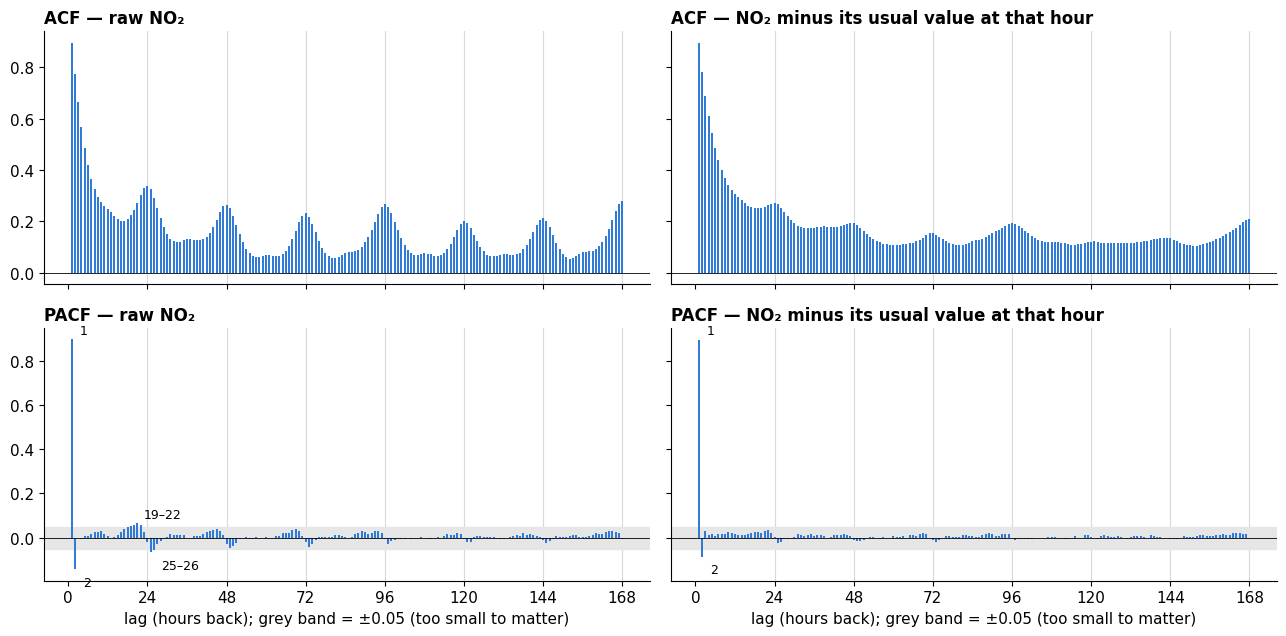

lags with |PACF raw| > 0.05:   [1, 2, 19, 20, 21, 22, 25, 26]
lags with |PACF resid| > 0.05: [1, 2]


,ACF raw,PACF raw,ACF minus usual,PACF minus usual
1,0.896,0.896,0.894,0.894
2,0.775,-0.142,0.781,-0.086
3,0.665,-0.003,0.688,0.033
6,0.419,0.008,0.486,0.009
12,0.249,0.009,0.307,0.019
21,0.272,0.066,0.256,0.031
22,0.303,0.059,0.263,0.034
23,0.329,0.027,0.270,0.023
24,0.339,-0.018,0.272,0.006
25,0.325,-0.066,0.266,-0.022


In [44]:
K = 168
TRAIN = SPLIT == "train"
def pooled_acf(x, K):
    """Correlation of NO2 with NO2 k hours earlier, same sensor, train rows; each sensor standardised first."""
    s = pd.Series(np.where(TRAIN, x, np.nan))
    z = ((s - s.groupby(SID).transform("mean")) / s.groupby(SID).transform("std")).to_numpy()
    r = np.empty(K)
    for k in range(1, K + 1):
        a, b = z[k:], z[:-k]
        ok = (SID[k:] == SID[:-k]) & ~np.isnan(a) & ~np.isnan(b)
        r[k - 1] = np.corrcoef(a[ok], b[ok])[0, 1]
    return r

def pacf_from_acf(r):
    """Durbin-Levinson recursion: partial autocorrelation from the autocorrelations."""
    K = len(r); rho = np.r_[1.0, r]; phi = np.zeros((K + 1, K + 1)); out = np.empty(K)
    for k in range(1, K + 1):
        phi[k, k] = (rho[k] - phi[k - 1, 1:k] @ rho[1:k][::-1]) / (1 - phi[k - 1, 1:k] @ rho[1:k])
        phi[k, 1:k] = phi[k - 1, 1:k] - phi[k, k] * phi[k - 1, 1:k][::-1]
        out[k - 1] = phi[k, k]
    return out

key = SID * 24 + HOUR
ok = TRAIN & ~np.isnan(NO2)
usual = np.bincount(key[ok], weights=NO2[ok], minlength=key.max() + 1) / np.maximum(np.bincount(key[ok], minlength=key.max() + 1), 1)
acf_raw, acf_res = pooled_acf(NO2, K), pooled_acf(NO2 - usual[key], K)    # raw | minus sensor x hour-of-day mean
pacf_raw, pacf_res = pacf_from_acf(acf_raw), pacf_from_acf(acf_res)

lags = np.arange(1, K + 1)
fig, axes = plt.subplots(2, 2, figsize=(13, 6.5), sharex=True, sharey="row")
for ax, vals, title in [(axes[0, 0], acf_raw, "ACF — raw NO₂"), (axes[0, 1], acf_res, "ACF — NO₂ minus its usual value at that hour"),
                        (axes[1, 0], pacf_raw, "PACF — raw NO₂"), (axes[1, 1], pacf_res, "PACF — NO₂ minus its usual value at that hour")]:
    ax.vlines(lags, 0, vals, lw=1.4, color="#2a78d6")
    for d in range(24, K + 1, 24):
        ax.axvline(d, color="0.85", lw=0.8, zorder=0)
    ax.axhline(0, color="k", lw=0.6); ax.grid(False); ax.set_xticks(range(0, K + 1, 24))
    if "PACF" in title:
        ax.axhspan(-0.05, 0.05, color="0.9", zorder=0)
        sig = lags[np.abs(vals) > 0.05]
        groups_ = np.split(sig, np.flatnonzero(np.diff(sig) > 1) + 1) if len(sig) else []
        for gk in groups_:
            for part in ([gk[vals[gk - 1] > 0], gk[vals[gk - 1] < 0]]):
                if len(part) == 0:
                    continue
                lab = str(part[0]) if len(part) == 1 else f"{part[0]}–{part[-1]}"
                v = vals[part - 1]; up = v[0] > 0
                ax.annotate(lab, (part.mean(), v.max() if up else v.min()), xytext=(6, 4 if up else -12),
                            textcoords="offset points", ha="left", fontsize=9)
    ax.set_title(title, loc="left")
for ax in axes[1]:
    ax.set_xlabel("lag (hours back); grey band = ±0.05 (too small to matter)")
save("s4_acf_pacf")
print("lags with |PACF raw| > 0.05:  ", [int(k) for k in lags[np.abs(pacf_raw) > 0.05]])
print("lags with |PACF resid| > 0.05:", [int(k) for k in lags[np.abs(pacf_res) > 0.05]])
pd.DataFrame({"ACF raw": acf_raw, "PACF raw": pacf_raw, "ACF minus usual": acf_res, "PACF minus usual": pacf_res},
             index=lags).loc[[1, 2, 3, 6, 12, 21, 22, 23, 24, 25, 26, 48, 165, 168]]

---
# Slide 5 — Testing the lag sets
**On the slide:** the bar chart (`s5_lag_sets.png`); the chosen set has an orange outline.

**What I did**
- I compared 6 lag sets with the same simple model (linear regression, lags only), scored on validation. The code picks the set with the **lowest average val MAE**; I don't pick by hand.
  - **A, old:** 0, 1, 2, 3, 6, 12, 24 (last week's hand-picked set)
  - **B, PACF re-centred on target:** 0, 1, 2 + yesterday at the target hour ±1
  - **C:** B + same hour last week
  - **D, PACF lags:** 0 + every lag the PACF flags (1, 2, 19–22, 25, 26)
  - **E, PACF lags shifted to the target hour:** a variant that turned out worse
  - **F, PACF lags + last week:** D + same hour last week

****
- "All PACF-based sets beat the old set, and the gain grows with the horizon."
- "**Winner: F, the PACF lags + same hour last week**, at every horizon. At t+3, MAE goes from **2.88 (old set A) → 2.78 (F)**; skill from 5.9% → 9.4%. The improvement over A is clear at t+3 (the interval excludes 0)."
- "F vs the next-best sets is a small difference (hundredths of a ppb), but it's the best and fully based on what the PACF found, plus one weekly lag."
- "At t+1 all sets are close: the last hour already tells almost everything."
- "**All models from here on use set F**: 10 lags = NO₂ now, 1, 2, 19, 20, 21, 22, 25, 26 hours ago, and the same hour last week."


PACF lags: [1, 2, 19, 20, 21, 22, 25, 26]


lags (hours before t)   MAE  Skill%      change vs A [95% CI]
horizon lag set                                                                                                       
t+1     A: old                                         [0, 1, 2, 3, 6, 12, 24] 1.661   1.759   +0.000 [+0.000, +0.000]
        B: PACF, re-centred on target                    [0, 1, 2, 22, 23, 24] 1.646   2.642  -0.015 [-0.031, -0.000]*
        C: B + last week                            [0, 1, 2, 22, 23, 24, 167] 1.644   2.750   -0.017 [-0.036, +0.001]
        D: PACF lags                         [0, 1, 2, 19, 20, 21, 22, 25, 26] 1.643   2.814   -0.018 [-0.037, +0.001]
        E: PACF lags shifted to target          [0, 1, 18, 19, 20, 21, 24, 25] 1.647   2.620   -0.015 [-0.030, +0.001]
        F: PACF lags + last week        [0, 1, 2, 19, 20, 21, 22, 25, 26, 167] 1.641   2.939   -0.020 [-0.044, +0.002]
t+2     A: old                                         [0, 1, 2, 3, 6, 12, 24] 2.415   3.411   +0.000 [+0.000, +0.000]
        B: PACF, re-centred on target                    [0, 1, 2, 21, 22, 23] 2.378   4.912  -0.038 [-0.079, -0.002]*
        C: B + last week                            [0, 1, 2, 21, 22, 23, 166] 2.367   5.329  -0.048 [-0.102, -0.001]*
        D: PACF lags                         [0, 1, 2, 19, 20, 21, 22, 25, 26] 2.367   5.351   -0.049 [-0.104, +0.003]
        E: PACF lags shifted to target             [0, 17, 18, 19, 20, 23, 24] 2.380   4.809   -0.035 [-0.078, +0.010]
        F: PACF lags + last week        [0, 1, 2, 19, 20, 21, 22, 25, 26, 166] 2.355   5.806   -0.060 [-0.132, +0.003]
t+3     A: old                                         [0, 1, 2, 3, 6, 12, 24] 2.882   5.927   +0.000 [+0.000, +0.000]
        B: PACF, re-centred on target                    [0, 1, 2, 20, 21, 22] 2.821   7.901  -0.060 [-0.120, -0.003]*
        C: B + last week                            [0, 1, 2, 20, 21, 22, 165] 2.795   8.771  -0.087 [-0.173, -0.012]*
        D: PACF lags                         [0, 1, 2, 19, 20, 21, 22, 25, 26] 2.803   8.493   -0.079 [-0.164, +0.002]
        E: PACF lags shifted to target             [0, 16, 17, 18, 19, 22, 23] 2.822   7.887   -0.060 [-0.125, +0.005]
        F: PACF lags + last week        [0, 1, 2, 19, 20, 21, 22, 25, 26, 165] 2.775   9.402  -0.106 [-0.218, -0.009]*

chosen: F: PACF lags + last week {'t+1': ['no2', 'L1', 'L2', 'L19', 'L20', 'L21', 'L22', 'L25', 'L26', 'L167'], 't+2': ['no2', 'L1', 'L2', 'L19', 'L20', 'L21', 'L22', 'L25', 'L26', 'L166'], 't+3': ['no2', 'L1', 'L2', 'L19', 'L20', 'L21', 'L22', 'L25', 'L26', 'L165']}


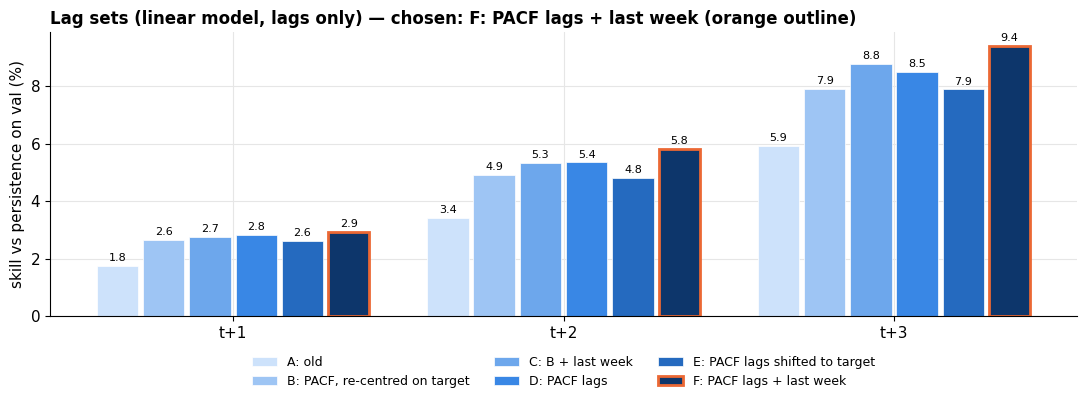

In [45]:
def fit_ols(cols, h, idx, chunk=300_000):
    """Linear regression on standardised columns (mean/sd from the fitting rows only), solved in chunks."""
    mu = np.array([m[c].to_numpy()[idx].astype(np.float64).mean() for c in cols])
    sd = np.array([m[c].to_numpy()[idx].astype(np.float64).std() for c in cols]); sd[sd == 0] = 1.0
    p = len(cols) + 1; A, b = np.zeros((p, p)), np.zeros(p)
    for i in range(0, len(idx), chunk):
        j = idx[i:i + chunk]; Z = np.c_[np.ones(len(j)), (X(cols, j) - mu) / sd]
        A += Z.T @ Z; b += Z.T @ Y(h, j)
    return {"cols": cols, "mu": mu, "sd": sd, "w": np.linalg.solve(A + 1e-6 * np.eye(p), b)}
def predict_ols(mod, idx):
    return mod["w"][0] + ((X(mod["cols"], idx) - mod["mu"]) / mod["sd"]) @ mod["w"][1:]

PACF_LAGS = [int(k) for k in lags[np.abs(pacf_raw) > 0.05]]          # from slide 4: every lag with |PACF raw| > 0.05
def lag_sets(h):
    """Candidate lag sets, in hours before t (0 = NO2 now)."""
    return {"A: old":                        [0, 1, 2, 3, 6, 12, 24],
            "B: PACF, re-centred on target":  [0, 1, 2, 23 - h, 24 - h, 25 - h],
            "C: B + last week":               [0, 1, 2, 23 - h, 24 - h, 25 - h, 168 - h],
            "D: PACF lags":                   [0] + PACF_LAGS,
            "E: PACF lags shifted to target": sorted({0} | {k - h for k in PACF_LAGS if k >= h}),
            "F: PACF lags + last week":       [0] + PACF_LAGS + [168 - h]}
print("PACF lags:", PACF_LAGS)

rows = []
for h in HORIZONS:
    tr, va = ROWS[h]["train"], ROWS[h]["val"]; y = Y(h, va)
    preds = {n: predict_ols(fit_ols([lag_col(k) for k in ks], h, tr), va) for n, ks in lag_sets(h).items()}
    for n, p in preds.items():
        rows.append({"horizon": f"t+{h}", "lag set": n, "lags (hours before t)": lag_sets(h)[n],
                     "MAE": np.abs(p - y).mean(), "Skill%": scores(y, p, NO2[va])["Skill%"],
                     "change vs A [95% CI]": fmt_ci(delta_mae_ci(y, preds["A: old"], p, BLOCK[va]))})
lag_tbl = pd.DataFrame(rows)
display(lag_tbl.set_index(["horizon", "lag set"]))
CHOSEN = lag_tbl.groupby("lag set")["MAE"].mean().idxmin()
def LAGS(h):
    return [lag_col(k) for k in lag_sets(h)[CHOSEN]]
print("chosen:", CHOSEN, {f"t+{h}": LAGS(h) for h in HORIZONS})

sk = lag_tbl.pivot(index="horizon", columns="lag set", values="Skill%")
fig, ax = plt.subplots(figsize=(11, 4.2))
shades = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#0d366b"]
w = 0.14
for i, n in enumerate(sk.columns):
    bars = ax.bar(np.arange(3) + (i - 2.5) * w, sk[n], w - 0.015, color=shades[i], label=n,
                  edgecolor="#eb6834" if n == CHOSEN else "white", linewidth=2 if n == CHOSEN else 0.5)
    ax.bar_label(bars, fmt="%.1f", fontsize=8, padding=2)
ax.set_xticks(range(3), sk.index); ax.set_ylabel("skill vs persistence on val (%)")
ax.set_title(f"Lag sets (linear model, lags only) — chosen: {CHOSEN} (orange outline)", loc="left")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False, fontsize=9)
save("s5_lag_sets")

---
# Slide 6 — Feature groups, one at a time
**On the slide:** the heatmap (`s6_feature_groups.png`). Numbers = change in val MAE (ppb); `*` = the interval excludes 0.

**The 4 feature groups**
- **time:** hour of day, day of week, holiday
- **weather:** temperature, humidity, wind speed, wind direction, calm
- **city:** citywide average NO₂ right now
- **geo:** tree canopy, pavement, distance to downtown, expressway length, industrial area near the sensor

**Two tests per group** (linear model, lags from set C)
- **Add-one** (left): lags + this group only → "does this group carry *any* useful information?" Blue = helps.
- **Drop-one** (right): all groups minus this one → "is this group *needed*, or do the others cover it?" Red = needed.

****
- "Last week we stacked features one after another, so each group's value depended on the order. Now each group is tested on its own."
- "**Weather now helps** at every horizon (−0.024 ppb at t+3). In our first split it made things *worse*, because training had no summer. So the split fix worked."
- "**geo** gives a tiny but consistent gain. **city** helps only at 1 hour."
- "**time** doesn't help the *linear* model. A straight-line model can't follow a daily pattern that changes shape by season, but the GAM and GBM use it well (next slide)."
- "Honest caveat: with only ~8 validation weeks, none of these gains are big enough to be *proven* one group at a time. So I don't throw groups away here; I compare 'all features' vs 'lags only' in each model instead."
- Effects are small (hundredths of a ppb) because the lags already carry most of the information.

,,add-one change [CI] (<0 = helps),drop-one change [CI] (>0 = needed)
group,horizon,,
time,t+1,"+0.002 [-0.004, +0.008]","-0.003 [-0.008, +0.005]"
weather,t+1,"-0.011 [-0.028, +0.008]","+0.007 [-0.005, +0.018]"
city,t+1,"-0.006 [-0.010, -0.002]*","+0.001 [-0.007, +0.009]"
geo,t+1,"-0.000 [-0.000, +0.000]","+0.000 [-0.001, +0.001]"
time,t+2,"+0.005 [-0.013, +0.022]","-0.007 [-0.024, +0.015]"
weather,t+2,"-0.022 [-0.061, +0.025]","+0.017 [-0.021, +0.050]"
city,t+2,"-0.001 [-0.008, +0.006]","-0.003 [-0.010, +0.003]"
geo,t+2,"-0.001 [-0.001, -0.000]*","+0.001 [-0.001, +0.002]"
time,t+3,"+0.007 [-0.022, +0.034]","-0.012 [-0.039, +0.026]"


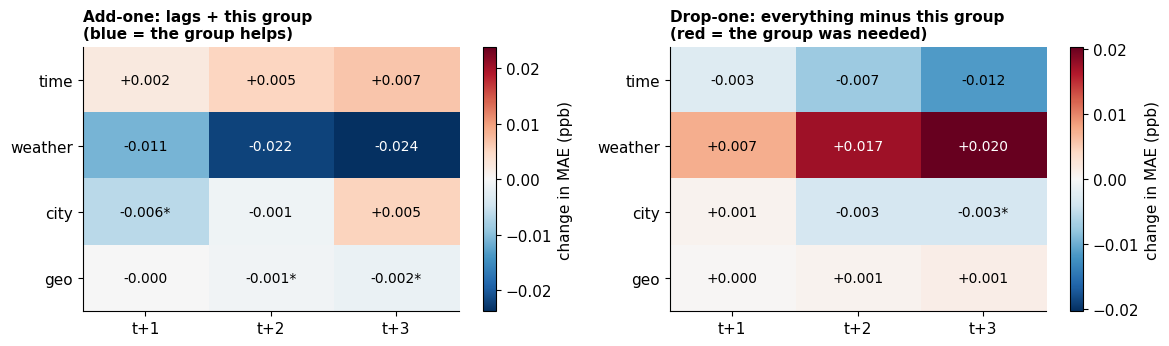

In [46]:
rows = []
for h in HORIZONS:
    tr, va = ROWS[h]["train"], ROWS[h]["val"]; y = Y(h, va)
    base, full = LAGS(h), LAGS(h) + ALL_GROUP_COLS
    p_base, p_full = predict_ols(fit_ols(base, h, tr), va), predict_ols(fit_ols(full, h, tr), va)
    for g, gc in GROUPS.items():
        p_add  = predict_ols(fit_ols(base + gc, h, tr), va)
        p_drop = predict_ols(fit_ols([c for c in full if c not in gc], h, tr), va)
        rows.append({"horizon": f"t+{h}", "group": g,
                     "add": delta_mae_ci(y, p_base, p_add, BLOCK[va]), "drop": delta_mae_ci(y, p_full, p_drop, BLOCK[va])})
grp = pd.DataFrame(rows)
display(grp.assign(**{"add-one change [CI] (<0 = helps)": grp["add"].map(fmt_ci),
                      "drop-one change [CI] (>0 = needed)": grp["drop"].map(fmt_ci)})
           .drop(columns=["add", "drop"]).set_index(["group", "horizon"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, col, title in [(axes[0], "add", "Add-one: lags + this group\n(blue = the group helps)"),
                       (axes[1], "drop", "Drop-one: everything minus this group\n(red = the group was needed)")]:
    est = grp.pivot(index="group", columns="horizon", values=col).loc[list(GROUPS)]
    vals = est.map(lambda t: t[0]).to_numpy(float); sig = est.map(lambda t: t[1] > 0 or t[2] < 0).to_numpy()
    lim = np.abs(vals).max()
    im = ax.imshow(vals, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    for i in range(vals.shape[0]):
        for j in range(vals.shape[1]):
            ax.text(j, i, f"{vals[i, j]:+.3f}{'*' if sig[i, j] else ''}", ha="center", va="center", fontsize=10,
                    color="white" if abs(vals[i, j]) > 0.6 * lim else "black")
    ax.set_xticks(range(3), est.columns); ax.set_yticks(range(len(GROUPS)), list(GROUPS)); ax.grid(False)
    ax.set_title(title, loc="left", fontsize=11); plt.colorbar(im, ax=ax, label="change in MAE (ppb)")
save("s6_feature_groups")

---
# Slide 7 — Models compared on validation
**On the slide:** the skill bar chart (`s7_models_val.png`). Solid = all features, hatched = lags only.

**The 3 model types**
- **Linear regression:** every input has a straight-line effect. Last week's model.
- **GAM (generalised additive model):** like linear, but each weather/time effect can be a **smooth curve**. The forecast = lags + a curve for temperature + a curve for humidity + a curve for wind speed + a daily curve (separate for weekdays and weekends) + a wind-direction map + a small offset per sensor. One smoothness setting, chosen on val (alpha = 1000).
- **GBM (gradient boosting):** hundreds of small decision trees added together. It can learn "it depends" effects, like wind mattering more at rush hour.
- Each model with **all features** and with **lags only** → 6 models, same rows, same metrics.

****
- "**Every model beats persistence** at every horizon; all intervals exclude 0."
- "**Extra features help every model**: solid bars beat hatched bars. With lags only, all three models are about the same (~9.4–9.8% at t+3), because a fancier model can't help if it has nothing extra to work with."
- "**GBM with all features is best** on validation: skill **7.2% / 11.4% / 15.4%**. Then GAM (5.1 / 8.7 / 12.8), then linear (3.6 / 6.3 / 9.7)."
- "Skill grows with the horizon: at 1 hour, persistence is very hard to beat."
- R² on val at t+3: GBM 0.58 vs persistence 0.35 (only if someone asks about R²).

In [47]:
NFIT = 500_000
def subsample(idx, n=NFIT, seed=SEED):
    return idx if len(idx) <= n else np.sort(np.random.default_rng(seed).choice(idx, n, replace=False))

class SplineGAM:
    """GAM = lags (straight lines) + smooth curves + sensor offsets, fitted as one penalised (ridge) regression."""
    def __init__(self, lags, groups, alpha):
        self.lags, self.groups, self.alpha = lags, list(groups), alpha
        self.lin = lags + (["no2_city"] if "city" in groups else []) + (["is_holiday"] if "time" in groups else []) \
                        + (["is_calm"] if "weather" in groups else [])
        self.smooth = ["temp", "rhum", "wspd_ms"] if "weather" in groups else []
    def _design(self, idx, fit=False):
        Zl = X(self.lin, idx)
        if fit:
            self.mu, self.sd = Zl.mean(0), Zl.std(0) + 1e-9
            self.sp = {v: SplineTransformer(n_knots=8, degree=3, knots="quantile", extrapolation="constant",
                                            include_bias=False).fit(X([v], idx)) for v in self.smooth}
            self.hr = SplineTransformer(n_knots=9, degree=3, knots=np.linspace(0, 24, 9).reshape(-1, 1),
                                        extrapolation="periodic").fit(np.arange(24).reshape(-1, 1))
            if "weather" in self.groups:
                self.wu = SplineTransformer(n_knots=5, degree=3, knots="quantile", extrapolation="constant").fit(X(["wind_u"], idx))
                self.wv = SplineTransformer(n_knots=5, degree=3, knots="quantile", extrapolation="constant").fit(X(["wind_v"], idx))
        blocks, self.slices, start = [], {}, 0
        def add(name, B):
            nonlocal start
            blocks.append(sp.csr_matrix(B)); self.slices[name] = slice(start, start + B.shape[1]); start += B.shape[1]
        add("linear", (Zl - self.mu) / self.sd)
        for v in self.smooth:
            add(v, self.sp[v].transform(X([v], idx)))
        if "time" in self.groups:
            Bh = self.hr.transform(HOUR[idx].reshape(-1, 1).astype(float)); wk = m["weekend"].to_numpy()[idx].reshape(-1, 1)
            add("hour_weekday", Bh * (1 - wk)); add("hour_weekend", Bh * wk)
        if "weather" in self.groups:
            Bu, Bv = self.wu.transform(X(["wind_u"], idx)), self.wv.transform(X(["wind_v"], idx))
            add("wind", (Bu[:, :, None] * Bv[:, None, :]).reshape(len(idx), -1))
        if "geo" in self.groups:
            add("sensor", sp.csr_matrix((np.ones(len(idx)), (np.arange(len(idx)), SID[idx])), shape=(len(idx), SID.max() + 1)))
        return sp.hstack(blocks, format="csr")
    def fit(self, h, idx):
        self.model = Ridge(alpha=self.alpha, solver="sparse_cg", tol=1e-6, max_iter=3000).fit(self._design(idx, True), Y(h, idx))
        return self
    def predict(self, idx, chunk=400_000):
        return np.concatenate([self.model.predict(self._design(idx[i:i + chunk])) for i in range(0, len(idx), chunk)])

INPUT_SETS = {"all features": list(GROUPS), "lags only": []}
MODEL_NAMES = [f"{k} ({s})" for k in ["Linear", "GAM", "GBM"] for s in INPUT_SETS]
ALPHA = None
def fit_model(name, h, fit_idx, alpha=None):
    """Fit one of MODEL_NAMES on fit_idx; returns a predict function."""
    kind, inputs = name[:-1].split(" (")
    groups = INPUT_SETS[inputs]; cols = LAGS(h) + [c for g in groups for c in GROUPS[g]]
    if kind == "Linear":
        mod = fit_ols(cols, h, fit_idx); return lambda j: predict_ols(mod, j)
    if kind == "GAM":
        mod = SplineGAM(LAGS(h), groups, alpha or ALPHA).fit(h, subsample(fit_idx)); return mod.predict
    sub = subsample(fit_idx)
    mod = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, max_leaf_nodes=63, min_samples_leaf=200,
                                        l2_regularization=1.0, early_stopping=False, random_state=SEED).fit(X(cols, sub), Y(h, sub))
    return lambda j: mod.predict(X(cols, j))

# GAM smoothness: chosen on val at t+3 (bigger alpha = smoother curves)
tr, va = ROWS[3]["train"], ROWS[3]["val"]; y = Y(3, va)
alpha_mae = {a: np.abs(fit_model("GAM (all features)", 3, tr, alpha=a)(va) - y).mean() for a in [10, 100, 1_000, 10_000, 100_000]}
ALPHA = min(alpha_mae, key=alpha_mae.get)
print("GAM alpha (val MAE):", {a: round(v, 4) for a, v in alpha_mae.items()}, "-> chosen", ALPHA)

GAM alpha (val MAE): {10: np.float64(2.675), 100: np.float64(2.6741), 1000: np.float64(2.6711), 10000: np.float64(2.6901), 100000: np.float64(2.7987)} -> chosen 1000


MAE  RMSE   Bias    R2  Skill% change vs persistence [CI]
horizon model                                                                            
t+1     Persistence           1.691 2.522  0.024 0.792   0.000                           
        Linear (all features) 1.631 2.366 -0.004 0.817   3.567   -0.060 [-0.094, -0.031]*
        Linear (lags only)    1.641 2.406  0.011 0.810   2.939   -0.050 [-0.078, -0.025]*
        GAM (all features)    1.605 2.325 -0.001 0.823   5.055   -0.085 [-0.126, -0.057]*
        GAM (lags only)       1.642 2.406  0.005 0.810   2.881   -0.049 [-0.077, -0.024]*
        GBM (all features)    1.571 2.275  0.026 0.831   7.084   -0.120 [-0.175, -0.064]*
        GBM (lags only)       1.640 2.405  0.021 0.811   3.013   -0.051 [-0.087, -0.020]*
t+2     Persistence           2.501 3.675  0.047 0.555   0.000                           
        Linear (all features) 2.343 3.302 -0.015 0.640   6.310   -0.158 [-0.242, -0.088]*
        Linear (lags only)    2.355 3.366  0.019 0.626   5.806   -0.145 [-0.213, -0.086]*
        GAM (all features)    2.282 3.209  0.022 0.660   8.741   -0.219 [-0.319, -0.148]*
        GAM (lags only)       2.356 3.366  0.025 0.626   5.765   -0.144 [-0.211, -0.085]*
        GBM (all features)    2.211 3.107  0.108 0.682  11.596   -0.290 [-0.428, -0.139]*
        GBM (lags only)       2.347 3.357  0.066 0.628   6.144   -0.154 [-0.236, -0.085]*
t+3     Persistence           3.063 4.425  0.066 0.350   0.000                           
        Linear (all features) 2.766 3.809 -0.038 0.518   9.704   -0.297 [-0.430, -0.198]*
        Linear (lags only)    2.775 3.889  0.020 0.498   9.402   -0.288 [-0.395, -0.197]*
        GAM (all features)    2.671 3.670  0.013 0.553  12.802   -0.392 [-0.546, -0.283]*
        GAM (lags only)       2.775 3.890  0.021 0.498   9.412   -0.288 [-0.395, -0.197]*
        GBM (all features)    2.604 3.589  0.154 0.573  14.988   -0.459 [-0.665, -0.257]*
        GBM (lags only)       2.765 3.877  0.091 0.501   9.738   -0.298 [-0.420, -0.192]*

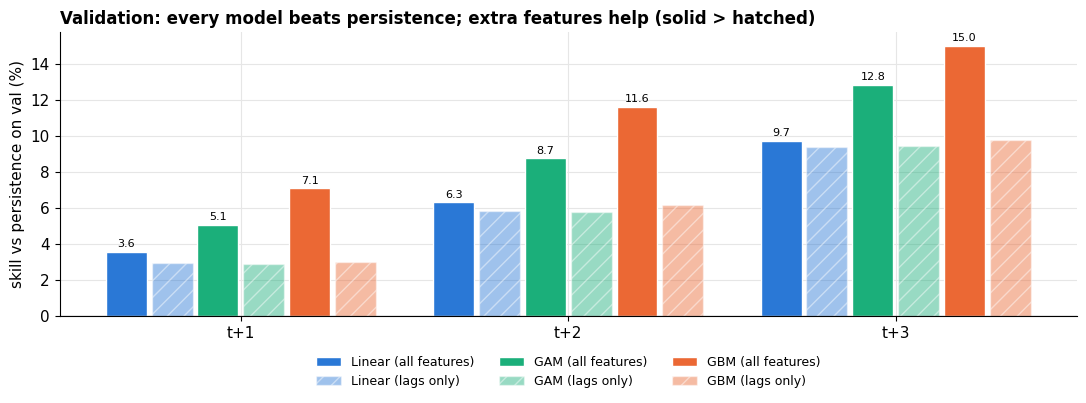

In [48]:
VAL_PRED, rows = {}, []
for h in HORIZONS:
    tr, va = ROWS[h]["train"], ROWS[h]["val"]; y = Y(h, va)
    preds = {"Persistence": NO2[va]}
    for name in MODEL_NAMES:
        preds[name] = fit_model(name, h, tr)(va)
    VAL_PRED[h] = preds
    for name, p in preds.items():
        rows.append({"horizon": f"t+{h}", "model": name, **scores(y, p, NO2[va]),
                     "change vs persistence [CI]": "" if name == "Persistence" else fmt_ci(delta_mae_ci(y, NO2[va], p, BLOCK[va]))})
val_tbl = pd.DataFrame(rows).set_index(["horizon", "model"])
display(val_tbl)

sk = val_tbl["Skill%"].unstack("model")[MODEL_NAMES]
fig, ax = plt.subplots(figsize=(11, 4.2))
w = 0.14
for i, n in enumerate(MODEL_NAMES):
    lagsonly = "lags only" in n
    bars = ax.bar(np.arange(3) + (i - 2.5) * w, sk[n], w - 0.015, color=colour(n), label=n,
                  alpha=0.45 if lagsonly else 1.0, hatch="//" if lagsonly else None, edgecolor="white")
    if not lagsonly:
        ax.bar_label(bars, fmt="%.1f", fontsize=8, padding=2)
ax.axhline(0, c="k", lw=0.8); ax.set_xticks(range(3), sk.index)
ax.set_ylabel("skill vs persistence on val (%)")
ax.set_title("Validation: every model beats persistence; extra features help (solid > hatched)", loc="left")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False, fontsize=9)
save("s7_models_val")

---
# Slide 8 — Choosing the final model
**On the slide:** the "what features add" chart (`s8_features_add.png`) + the rule as 3 bullets.

**My rule (set before I looked at test)**
1. Find the model with the lowest val MAE → **GBM (all features)** at every horizon.
2. For every other model: how much worse is it, with a 95% interval?
3. "Tied" = the interval includes 0 (not clearly worse). Among tied models, take the **simplest**.

****
- "At t+2 and t+3 only **GAM (all features)** is tied with GBM; everything else is clearly worse. At t+1 even the GAM is slightly but clearly worse (by 0.04 ppb), so GBM wins outright there."
- "So I keep **two models with two jobs**:
  - **GAM (all features)**: the simplest model that's as good as the best. I use it to **explain** (its curves are on the next slide).
  - **GBM (all features)**: the lowest error. I use it as the **forecaster**."
- "The chart shows what the extra features (time, weather, city, geo) add at t+3: GBM goes from **9.8% → 15.4%** skill, GAM from 9.4% → 12.8%, linear only 9.4% → 9.7%."
- "So the features matter, but you need a flexible model to use them."

**If someone asks:** *Why not just take the lowest MAE?* With only 8 val weeks, small differences can be luck; a simpler model is easier to explain and less likely to over-fit. That's why I report both.

val MAE   worse than best by [CI]  tied with best
horizon model (simple -> complex)                                                   
t+1     Linear (lags only)           1.641  +0.070 [+0.032, +0.110]*           False
        Linear (all features)        1.631  +0.059 [+0.023, +0.099]*           False
        GAM (lags only)              1.642  +0.071 [+0.032, +0.111]*           False
        GAM (all features)           1.605   +0.034 [-0.000, +0.067]            True
        GBM (lags only)              1.640  +0.069 [+0.033, +0.108]*           False
        GBM (all features)           1.571                      best            True
t+2     Linear (lags only)           2.355  +0.145 [+0.033, +0.248]*           False
        Linear (all features)        2.343  +0.132 [+0.024, +0.236]*           False
        GAM (lags only)              2.356  +0.146 [+0.034, +0.249]*           False
        GAM (all features)           2.282   +0.071 [-0.039, +0.165]            True
        GBM (lags only)              2.347  +0.136 [+0.028, +0.237]*           False
        GBM (all features)           2.211                      best            True
t+3     Linear (lags only)           2.775  +0.171 [+0.026, +0.317]*           False
        Linear (all features)        2.766  +0.162 [+0.022, +0.304]*           False
        GAM (lags only)              2.775  +0.171 [+0.026, +0.317]*           False
        GAM (all features)           2.671   +0.067 [-0.059, +0.188]            True
        GBM (lags only)              2.765  +0.161 [+0.028, +0.297]*           False
        GBM (all features)           2.604                      best            True

simplest model tied with the best (my explainer): {1: 'GAM (all features)', 2: 'GAM (all features)', 3: 'GAM (all features)'}
lowest val MAE (my forecaster): {1: 'GBM (all features)', 2: 'GBM (all features)', 3: 'GBM (all features)'}


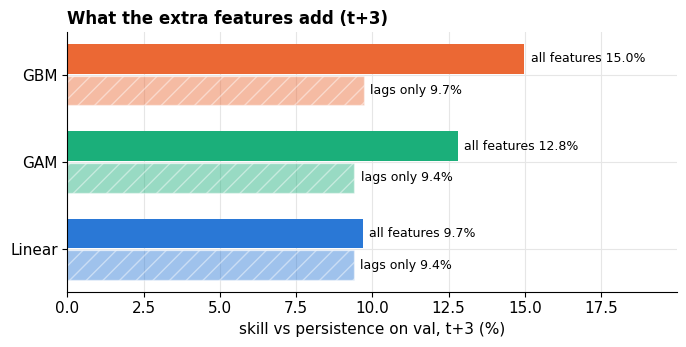

In [49]:
COMPLEXITY = [f"{k} ({s})" for k in ["Linear", "GAM", "GBM"] for s in ["lags only", "all features"]]
FINAL, rows = {}, []
for h in HORIZONS:
    va = ROWS[h]["val"]; y = Y(h, va); p = VAL_PRED[h]
    best = min(MODEL_NAMES, key=lambda n: np.abs(p[n] - y).mean())
    tied = []
    for n in COMPLEXITY:
        est, lo, hi = delta_mae_ci(y, p[best], p[n], BLOCK[va])
        if lo <= 0:
            tied.append(n)
        rows.append({"horizon": f"t+{h}", "model (simple -> complex)": n, "val MAE": np.abs(p[n] - y).mean(),
                     "worse than best by [CI]": "best" if n == best else fmt_ci((est, lo, hi)), "tied with best": lo <= 0})
    FINAL[h] = tied[0]
display(pd.DataFrame(rows).set_index(["horizon", "model (simple -> complex)"]))
FORECASTER = "GBM (all features)"
print("simplest model tied with the best (my explainer):", FINAL)
print("lowest val MAE (my forecaster):", {h: min(MODEL_NAMES, key=lambda n: np.abs(VAL_PRED[h][n] - Y(h, ROWS[h]['val'])).mean()) for h in HORIZONS})

# what do the features add? (t+3, val)
fig, ax = plt.subplots(figsize=(7, 3.6))
for i, k in enumerate(["Linear", "GAM", "GBM"]):
    a, b = sk.loc["t+3", f"{k} (lags only)"], sk.loc["t+3", f"{k} (all features)"]
    ax.barh(i + 0.18, b, 0.34, color=colour(k)); ax.barh(i - 0.18, a, 0.34, color=colour(k), alpha=0.45, hatch="//", edgecolor="white")
    ax.text(b + 0.2, i + 0.18, f"all features {b:.1f}%", va="center", fontsize=9)
    ax.text(a + 0.2, i - 0.18, f"lags only {a:.1f}%", va="center", fontsize=9)
ax.set_yticks(range(3), ["Linear", "GAM", "GBM"]); ax.set_xlim(0, sk.max().max() + 5)
ax.set_xlabel("skill vs persistence on val, t+3 (%)"); ax.set_title("What the extra features add (t+3)", loc="left")
save("s8_features_add")

---
# Slide 9 — GAM curves: how the forecast is adjusted
**On the slide:** the GAM curves (`s9_gam_curves.png`). Top: temperature, humidity, wind speed. Bottom: hour of day, wind map.

**How to read the curves**
- The GAM's forecast = **current NO₂ and lags** + **one adjustment per feature**, added together.
- Each curve shows **how much that one feature pushes the 3-hour-ahead forecast up or down (ppb)**, with everything else held the same.
- 0 = no adjustment. Above 0 = forecast pushed up; below 0 = pushed down.
- These are adjustments **on top of** what NO₂ is now, not "the total effect of weather on pollution".

****
- **Wind speed:** a smooth drop from **+0.7 ppb (calm) to about −0.8 ppb (10 m/s)**. Wind spreads pollution out, so the model lowers the forecast when it's windy.
- **Wind map** (where the wind blows toward): the red centre = **calm air → +0.9 ppb**. Bottom-left blue = wind blowing toward the south-west, i.e. **coming from the north-east, off Lake Michigan → −0.9 ppb** (clean lake air).
- **Hour of day:** the biggest adjustment (±2 ppb):
  - weekday forecast made at **2–4 am → pushed up ~+2 ppb**: the morning rush is coming in the next 3 hours.
  - made at **6–9 am → pushed down ~−2 ppb**: the morning peak is about to end.
  - afternoon → up again (evening rush). Weekends (grey) are flatter: less commuting.
- **Temperature:** cold → higher (+1.5 ppb at −15 °C vs −0.5 at 30 °C). Plausible: heating, and cold air traps pollution near the ground (inversions).
- **Humidity:** higher humidity → lower forecast (humid, rainy air masses tend to be cleaner).

**If someone asks:** *Is this causal?* No. It's how the forecast is adjusted, given everything else in the model.

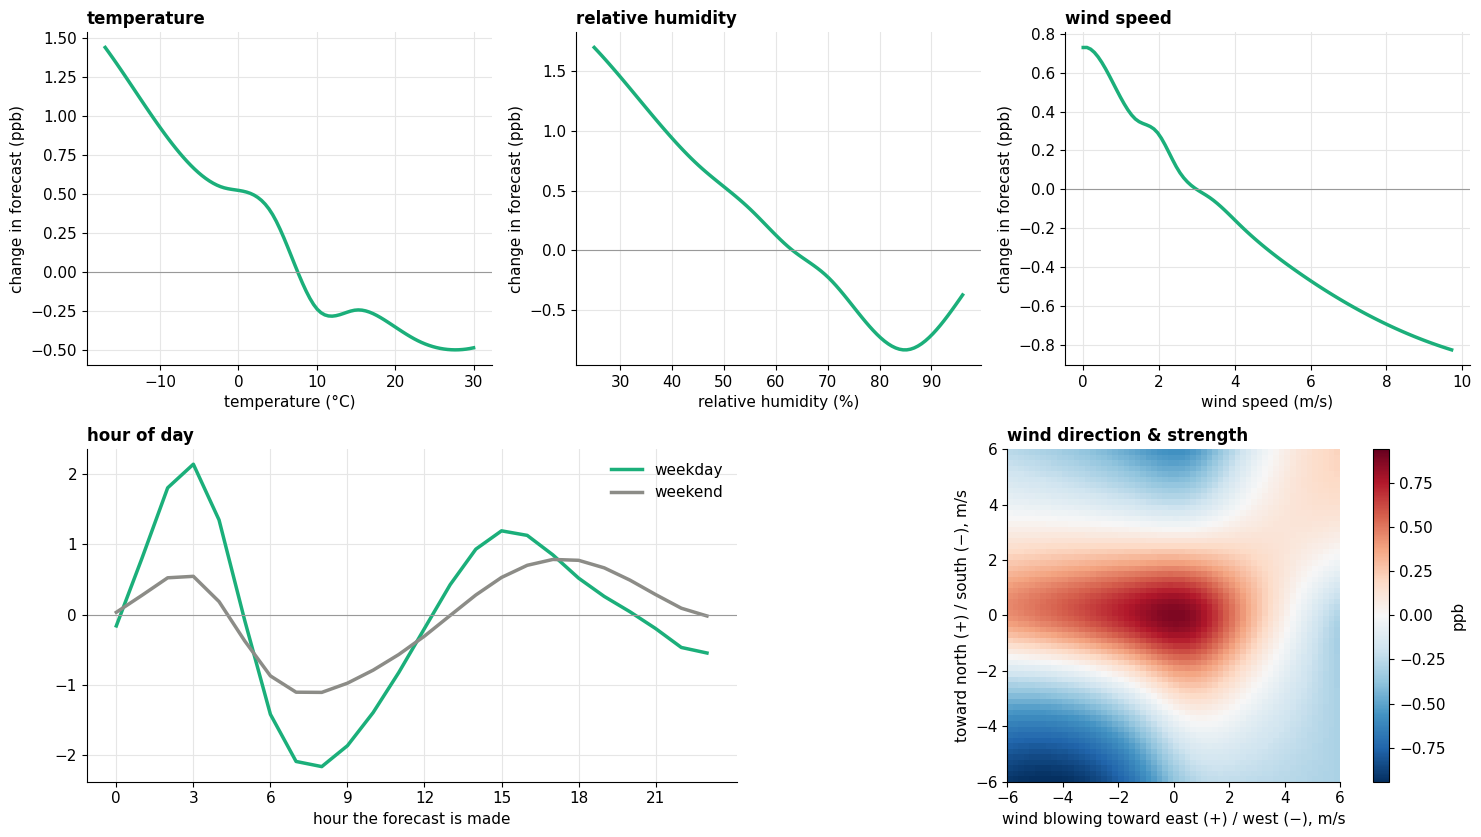

In [50]:
h = 3
gam = SplineGAM(LAGS(h), list(GROUPS), ALPHA).fit(h, subsample(ROWS[h]["train"]))
w = gam.model.coef_
tr_s = subsample(ROWS[h]["train"], 200_000)
fig = plt.figure(figsize=(15, 8.5)); gs = fig.add_gridspec(2, 6)
axes = [fig.add_subplot(gs[0, 0:2]), fig.add_subplot(gs[0, 2:4]), fig.add_subplot(gs[0, 4:6]),
        fig.add_subplot(gs[1, 0:3]), fig.add_subplot(gs[1, 3:6])]
units = {"temp": "temperature (°C)", "rhum": "relative humidity (%)", "wspd_ms": "wind speed (m/s)"}
for ax, v in zip(axes[:3], gam.smooth):
    xs = X([v], tr_s)
    grid = np.linspace(np.percentile(xs, 1), np.percentile(xs, 99), 100).reshape(-1, 1)
    f = gam.sp[v].transform(grid) @ w[gam.slices[v]] - (gam.sp[v].transform(xs) @ w[gam.slices[v]]).mean()
    ax.plot(grid, f, lw=2.5, c="#1baf7a"); ax.axhline(0, c="0.6", lw=0.8)
    ax.set_xlabel(units[v]); ax.set_ylabel("change in forecast (ppb)"); ax.set_title(units[v].split(" (")[0], loc="left")
hrs = np.arange(24).reshape(-1, 1).astype(float); Bh = gam.hr.transform(hrs)
for part, lab, c in [("hour_weekday", "weekday", "#1baf7a"), ("hour_weekend", "weekend", "#8c8c87")]:
    f = Bh @ w[gam.slices[part]]; axes[3].plot(hrs, f - f.mean(), lw=2.5, c=c, label=lab)
axes[3].axhline(0, c="0.6", lw=0.8); axes[3].legend(frameon=False)
axes[3].set_xticks([0, 3, 6, 9, 12, 15, 18, 21]); axes[3].set_xlabel("hour the forecast is made")
axes[3].set_title("hour of day", loc="left")
g = np.linspace(-6, 6, 60).reshape(-1, 1); Bu, Bv = gam.wu.transform(g), gam.wv.transform(g)
surf = np.einsum("ia,jb,ab->ji", Bu, Bv, w[gam.slices["wind"]].reshape(Bu.shape[1], Bv.shape[1])); surf -= surf.mean()
lim = np.abs(surf).max()
im = axes[4].imshow(surf, origin="lower", extent=[-6, 6, -6, 6], cmap="RdBu_r", vmin=-lim, vmax=lim)
axes[4].grid(False); axes[4].set_xlabel("wind blowing toward east (+) / west (−), m/s")
axes[4].set_ylabel("toward north (+) / south (−), m/s"); axes[4].set_title("wind direction & strength", loc="left")
plt.colorbar(im, ax=axes[4], label="ppb")
save("s9_gam_curves")

---
# Slide 10 — Error analysis (val, t+3)
**On the slide:** `s10_errors.png` (error by NO₂ level + map) + one line on unseen sensors. All on validation, t+3.

- **By pollution level** (left):
  - Normal levels, **10–30 ppb (85% of hours)**: both models clearly beat persistence (e.g. 15–20 ppb: 2.4 vs 3.2 ppb).
  - **Very low (< 10) and very high (30+, 2% of hours)**: the models are *worse* than persistence (30+: GAM 8.2, GBM 7.5, persistence 7.3).
  - Why: the models pull toward the average. They are cautious about extremes, which is exactly where an alert matters most. This is my main weakness.
- **By sensor** (map): GBM beats persistence at **98% of the 269 sensors**; median skill **15.5%**. No region of the city where it fails.
- **Sensors the model never saw:** I hid 20% of the sensors (53), retrained on the rest, and scored the hidden ones. Skill only drops **14.3% → 11.7%** (GBM) and 11.8% → 10.6% (GAM). So the model works at new locations, which is useful if new sensors are added.

**If someone asks:** *How to fix the extremes?* Ideas for later: models that predict a range (quantiles) instead of one value, or a separate model for high-NO₂ hours.

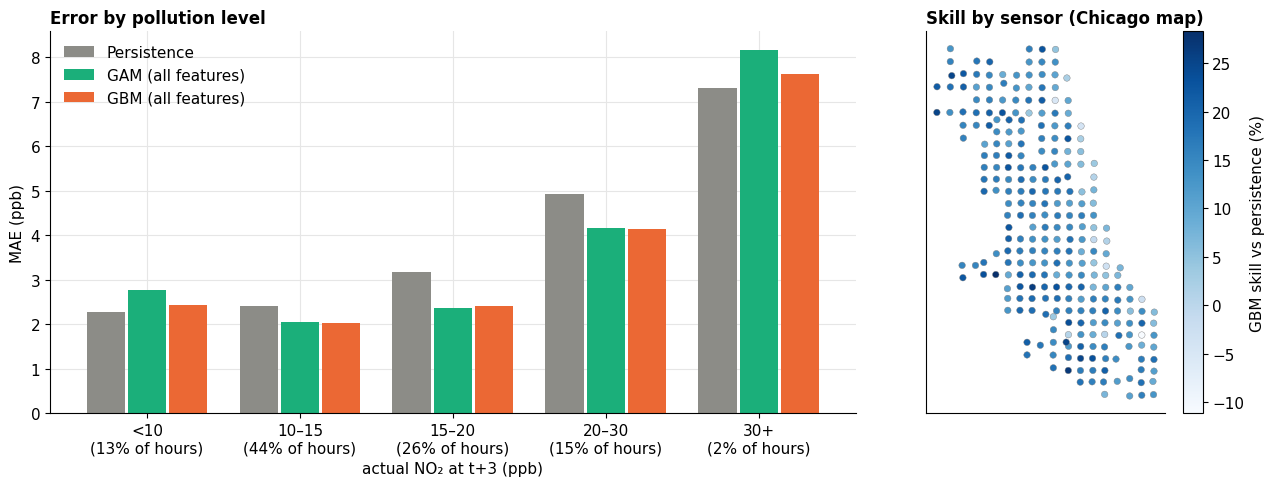

,Persistence,GAM (all features),GBM (all features),share of hours
level,,,,
<10,2.284,2.767,2.427,0.126
10–15,2.406,2.060,2.019,0.444
15–20,3.165,2.367,2.406,0.262
20–30,4.914,4.170,4.142,0.147
30+,7.298,8.167,7.617,0.022


GBM beats persistence at 98% of 269 sensors | median skill 15.3%


In [51]:
h = 3
va = ROWS[h]["val"]; y = Y(h, va)
EXPLAINER = FINAL[h]
cmp = ["Persistence", EXPLAINER, FORECASTER]
err = pd.DataFrame({"sid": SID[va], "y": y, **{n: np.abs(VAL_PRED[h][n] - y) for n in cmp}})
err["level"] = pd.cut(err["y"], [0, 10, 15, 20, 30, 1000], labels=["<10", "10–15", "15–20", "20–30", "30+"], right=False)
by_level = err.groupby("level", observed=True)[cmp].mean()
share = err.groupby("level", observed=True).size() / len(err)

per_sensor = err.groupby("sid").agg(persist=("Persistence", "mean"), model=(FORECASTER, "mean"))
per_sensor["skill%"] = 100 * (1 - per_sensor["model"] / per_sensor["persist"])
per_sensor = per_sensor.join(pd.DataFrame({"sid": SID[va], "lat": m["lat"].to_numpy()[va], "lon": m["lon"].to_numpy()[va]}).groupby("sid").first())

fig, ax = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [2.2, 1]})
for i, n in enumerate(cmp):
    ax[0].bar(np.arange(5) + (i - 1) * 0.27, by_level[n], 0.25, color=colour(n), label=n)
ax[0].set_xticks(range(5), [f"{l}\n({s:.0%} of hours)" for l, s in share.items()])
ax[0].set_xlabel("actual NO₂ at t+3 (ppb)"); ax[0].set_ylabel("MAE (ppb)")
ax[0].set_title("Error by pollution level", loc="left"); ax[0].legend(frameon=False)
sc = ax[1].scatter(per_sensor["lon"], per_sensor["lat"], c=per_sensor["skill%"], cmap="Blues", s=22, edgecolor="0.5", lw=0.3)
plt.colorbar(sc, ax=ax[1], label="GBM skill vs persistence (%)"); ax[1].set_aspect(1.3); ax[1].grid(False)
ax[1].set_xticks([]); ax[1].set_yticks([]); ax[1].set_title("Skill by sensor (Chicago map)", loc="left")
save("s10_errors")
display(by_level.assign(**{"share of hours": share}))
print(f"GBM beats persistence at {(per_sensor['skill%'] > 0).mean():.0%} of {len(per_sensor)} sensors | median skill {per_sensor['skill%'].median():.1f}%")

In [52]:
# unseen sensors: hold out 20% of sensors, retrain on the other 80%, score on the held-out sensors' val rows
tr = ROWS[h]["train"]
held = np.random.default_rng(SEED).choice(np.unique(SID), int(0.2 * SID.max()), replace=False)
tr80 = tr[~np.isin(SID[tr], held)]; va_h = va[np.isin(SID[va], held)]; y_h = Y(h, va_h)
rows = []
for name in dict.fromkeys([EXPLAINER, FORECASTER]):
    for lab, fit_idx in [("trained with these sensors", tr), ("these sensors never seen", tr80)]:
        rows.append({"model": name, "training": lab, **scores(y_h, fit_model(name, h, fit_idx)(va_h), NO2[va_h])})
print(f"held-out sensors: {len(held)}")
pd.DataFrame(rows).set_index(["model", "training"])[["MAE", "Skill%"]]

held-out sensors: 53


MAE  Skill%
model              training                                
GAM (all features) trained with these sensors 2.782  11.774
                   these sensors never seen   2.819  10.593
GBM (all features) trained with these sensors 2.714  13.949
                   these sensors never seen   2.762  12.404

---
# Slide 11 — Test set (scored once): GAM vs GBM
**On the slide:** `s11_test.png`: R² on test (left) and skill with the 4 week draws (right), plus big numbers.

**What I did**
- I refit both models on **train + validation** weeks with all settings frozen, and scored the **test weeks once**. Smoke weeks are not in test.

****
- **Test results** (skill vs persistence, t+1 / t+2 / t+3):
  - **GBM: 4.9% / 8.1% / 12.1%**; MAE 1.37 / 1.96 / 2.34 ppb; all intervals exclude 0.
  - **GAM: 3.1% / 5.5% / 9.0%**; MAE 1.40 / 2.01 / 2.42 ppb; clear at t+1 and t+3 (t+2 interval just touches 0).
  - **R² (left chart), because most people know it:** GBM **0.87 / 0.75 / 0.67**, GAM 0.87 / 0.75 / 0.66, persistence 0.85 / 0.68 / 0.53, climatology 0.15.
    - How I explain it: "R² is high even for persistence, because NO₂ an hour from now is close to NO₂ now. What matters is the **gap**: at 3 hours ahead we explain 67% of the ups and downs vs 53% for 'same as now', and the gap grows with the horizon."
- **4 random week draws** (right panel): I repeated the whole split with 3 other random seeds; only *which* weeks land in test changes. Like k-fold, but not k-fold.
  - **GBM beat the GAM in all 12 cases**; both always beat persistence.
  - Average GBM skill **6.6% / 10.7% / 15.0%** (t+3 range 11–20%). GAM 4.2% / 7.5% / 11.5%.
  - My main draw is at the low end, so the single test number is conservative.
- **By season (t+3):** GBM **summer 23%**, fall 12%, spring 11%, **winter 0.4%** (no better than persistence). Summer gains are biggest now that summer is in training. Winter NO₂ is hard to beat.
- **Takeaway:** "Our forecaster beats 'same as now' by about **5% at 1 hour and 12–15% at 3 hours**. The GAM explains *why* (hour of day, wind, temperature)."

**Caveats I mention**
- Only 8 test weeks (2 per season) → intervals are wide; more years of data would help most.
- One weather station (O'Hare) for the whole city; no hourly traffic data (hour of day is my traffic proxy).
- Side-by-side sensors disagree by 1.6–3.8 ppb, so gains at 1 hour are within sensor noise.
- Not comparable with our first notebook's 16%: that test was summer only (the easiest season).

In [53]:
TEST_PRED, rows = {}, []
for h in HORIZONS:
    fit_idx = np.sort(np.r_[ROWS[h]["train"], ROWS[h]["val"]])       # refit on train + val, settings frozen
    te = ROWS[h]["test"]; y = Y(h, te)
    preds = {"Persistence": NO2[te], "Climatology": climatology(h, fit_idx)[te]}
    for name in dict.fromkeys(["Linear (lags only)", EXPLAINER, FORECASTER]):
        preds[name] = fit_model(name, h, fit_idx)(te)
    TEST_PRED[h] = preds
    for name, p in preds.items():
        rows.append({"horizon": f"t+{h}", "model": name, **scores(y, p, NO2[te]),
                     "change vs persistence [CI]": "" if name == "Persistence" else fmt_ci(delta_mae_ci(y, NO2[te], p, BLOCK[te]))})
test_tbl = pd.DataFrame(rows).set_index(["horizon", "model"])
test_tbl

MAE  RMSE   Bias    R2   Skill% change vs persistence [CI]
horizon model                                                                          
t+1     Persistence        1.442 2.187 -0.015 0.850    0.000                           
        Climatology        4.005 5.203  0.860 0.149 -177.688   +2.563 [+1.978, +3.212]*
        Linear (lags only) 1.429 2.107  0.037 0.861    0.904    -0.013 [-0.053, +0.037]
        GAM (all features) 1.397 2.038 -0.018 0.870    3.134   -0.045 [-0.086, -0.002]*
        GBM (all features) 1.373 2.014 -0.031 0.872    4.784   -0.069 [-0.119, -0.016]*
t+2     Persistence        2.131 3.175 -0.030 0.684    0.000                           
        Climatology        4.005 5.206  0.856 0.149  -87.932   +1.874 [+1.243, +2.535]*
        Linear (lags only) 2.081 2.954  0.077 0.726    2.346    -0.050 [-0.149, +0.075]
        GAM (all features) 2.014 2.824 -0.002 0.750    5.526    -0.118 [-0.227, +0.002]
        GBM (all features) 1.948 2.785 -0.012 0.757    8.626   -0.184 [-0.308, -0.063]*
t+3     Persistence        2.660 3.876 -0.044 0.529    0.000                           
        Climatology        4.007 5.210  0.852 0.149  -50.663   +1.347 [+0.671, +1.995]*
        Linear (lags only) 2.530 3.492  0.112 0.618    4.882    -0.130 [-0.294, +0.069]
        GAM (all features) 2.421 3.312  0.030 0.656    8.987   -0.239 [-0.435, -0.032]*
        GBM (all features) 2.361 3.304  0.038 0.658   11.212   -0.298 [-0.535, -0.064]*

In [54]:
season_of_row = WEEK_START.map(dict(zip(weeks["week"], weeks["season"]))).to_numpy()
rows = []
for h in HORIZONS:
    te = ROWS[h]["test"]; y = Y(h, te)
    for s in ["fall", "winter", "spring", "summer"]:
        k = season_of_row[te] == s; mp = np.abs(NO2[te][k] - y[k]).mean()
        rows.append({"horizon": f"t+{h}", "season": s, **{f"Skill% {n.split(' (')[0]}": 100 * (1 - np.abs(TEST_PRED[h][n][k] - y[k]).mean() / mp)
                                                           for n in [EXPLAINER, FORECASTER]}})
season_tbl = pd.DataFrame(rows).set_index(["horizon", "season"])
season_tbl

Skill% GAM  Skill% GBM
horizon season                        
t+1     fall         0.795       2.684
        winter       0.493      -0.539
        spring       3.616       5.040
        summer       7.087      11.286
t+2     fall         1.113       8.021
        winter       1.364      -0.671
        spring       5.785       7.964
        summer      12.340      17.649
t+3     fall         4.357      10.568
        winter       2.168      -2.816
        spring       8.861      11.123
        summer      18.415      23.307

model         Linear (lags only)  GAM (all features)  GBM (all features)
horizon seed                                                            
t+1     0                  0.904               3.134               4.784
        1                  3.450               5.200               7.760
        2                  2.878               5.426               7.824
        3                 -0.043               3.119               6.097
t+2     0                  2.346               5.526               8.626
        1                  7.031              10.073              13.761
        2                  5.661               9.745              11.135
        3                  0.549               4.794               8.692
t+3     0                  4.882               8.987              11.212
        1                 11.203              15.377              19.796
        2                  9.327              14.376              16.470
        3                  2.701               7.408              11.101

mean    min    max
model              horizon                     
GAM (all features) t+1      4.220  3.119  5.426
                   t+2      7.534  4.794 10.073
                   t+3     11.537  7.408 15.377
GBM (all features) t+1      6.616  4.784  7.824
                   t+2     10.553  8.626 13.761
                   t+3     14.645 11.101 19.796
Linear (lags only) t+1      1.797 -0.043  3.450
                   t+2      3.897  0.549  7.031
                   t+3      7.028  2.701 11.203

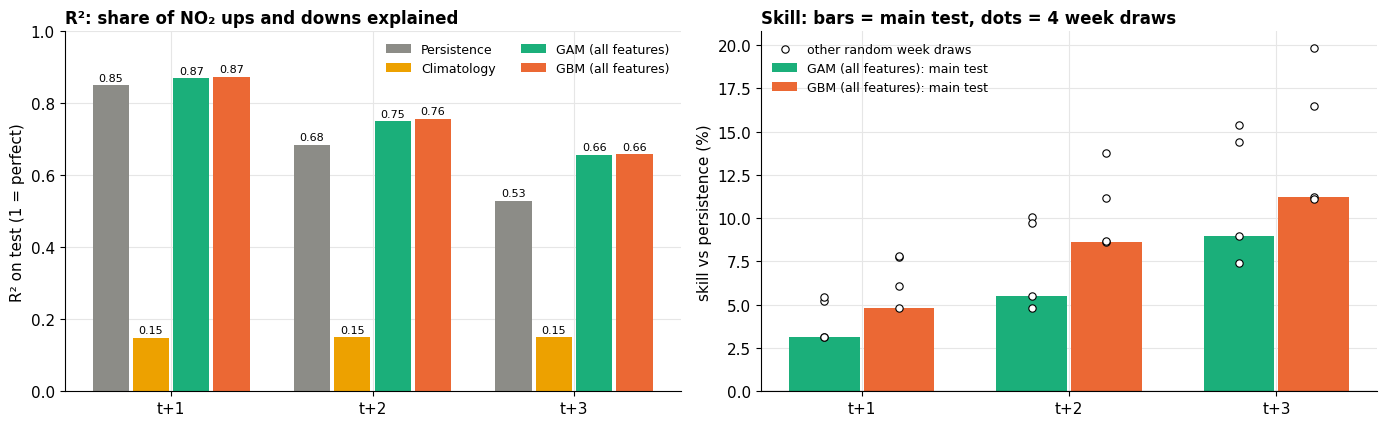

In [55]:
# robustness: 3 more random week draws (like k-fold, but not k-fold); all choices frozen, only the weeks change
rob = []
def record(seed, h, te, y, preds):
    for name, p in preds.items():
        rob.append({"seed": seed, "horizon": f"t+{h}", "model": name,
                    "Skill%": 100 * (1 - np.abs(p - y).mean() / np.abs(NO2[te] - y).mean())})
ROB_MODELS = list(dict.fromkeys(["Linear (lags only)", EXPLAINER, FORECASTER]))
for h in HORIZONS:
    te = ROWS[h]["test"]; record(SEED, h, te, Y(h, te), {n: TEST_PRED[h][n] for n in ROB_MODELS})
for seed in [1, 2, 3]:
    split_d, _ = make_split(seed); build_targets(split_d); rows_d = make_rows(split_d)
    for h in HORIZONS:
        fit_idx = np.sort(np.r_[rows_d[h]["train"], rows_d[h]["val"]]); te = rows_d[h]["test"]
        record(seed, h, te, Y(h, te), {n: fit_model(n, h, fit_idx)(te) for n in ROB_MODELS})
build_targets(SPLIT)                                                     # back to the main split
rob = pd.DataFrame(rob)
display(rob.pivot_table(index=["horizon", "seed"], columns="model", values="Skill%")[ROB_MODELS])
rob_sum = rob.groupby(["horizon", "model"])["Skill%"].agg(["mean", "min", "max"]).unstack("model")
display(rob.groupby(["model", "horizon"])["Skill%"].agg(["mean", "min", "max"]))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
r2_models = ["Persistence", "Climatology", EXPLAINER, FORECASTER]
for i, n in enumerate(r2_models):
    v = test_tbl.xs(n, level="model")["R2"]
    bars = ax[0].bar(np.arange(3) + (i - 1.5) * 0.2, v, 0.18, color=colour(n), label=n)
    ax[0].bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
ax[0].set_xticks(range(3), ["t+1", "t+2", "t+3"]); ax[0].set_ylim(0, 1)
ax[0].set_ylabel("R² on test (1 = perfect)"); ax[0].set_title("R²: share of NO₂ ups and downs explained", loc="left")
ax[0].legend(frameon=False, fontsize=9, ncol=2, loc="upper right")
for i, n in enumerate([EXPLAINER, FORECASTER]):
    v = test_tbl.xs(n, level="model")["Skill%"]
    ax[1].bar(np.arange(3) + (i - 0.5) * 0.36, v, 0.34, color=colour(n), label=f"{n}: main test")
    d = rob[rob["model"] == n]
    ax[1].scatter(d["horizon"].map({"t+1": 0, "t+2": 1, "t+3": 2}) + (i - 0.5) * 0.36, d["Skill%"], s=28,
                  color="white", edgecolor="k", lw=0.8, zorder=3, label="other random week draws" if i else None)
ax[1].axhline(0, c="k", lw=0.8); ax[1].set_xticks(range(3), ["t+1", "t+2", "t+3"])
ax[1].set_ylabel("skill vs persistence (%)"); ax[1].set_title("Skill: bars = main test, dots = 4 week draws", loc="left")
ax[1].legend(frameon=False, fontsize=9)
save("s11_test")

### Save the numbers for the PowerPoint (not a slide)
- Writes every number the slides use to `figures_slides/slide_data.json`, so the deck matches this notebook exactly.

In [56]:
import json
def tbl(df):
    return json.loads(df.reset_index().to_json(orient="records"))
slide_data = {
    "baselines_val": tbl(base_tbl), "lag_sets_val": tbl(lag_tbl.drop(columns=["lags (hours before t)"])), "chosen_lags": CHOSEN,
    "models_val": tbl(val_tbl.drop(columns=["change vs persistence [CI]"])),
    "error_by_level": tbl(by_level.assign(share=share)), "sensors_beating": float((per_sensor["skill%"] > 0).mean()),
    "sensor_median_skill": float(per_sensor["skill%"].median()),
    "test": tbl(test_tbl.drop(columns=["change vs persistence [CI]"])), "season": tbl(season_tbl), "robust": tbl(rob),
    "explainer": EXPLAINER, "forecaster": FORECASTER, "alpha": ALPHA, "pacf_lags": PACF_LAGS,
}
json.dump(slide_data, open(f"{FIGS}/slide_data.json", "w"), indent=1)
print("saved", list(slide_data))

saved ['baselines_val', 'lag_sets_val', 'chosen_lags', 'models_val', 'error_by_level', 'sensors_beating', 'sensor_median_skill', 'test', 'season', 'robust', 'explainer', 'forecaster', 'alpha', 'pacf_lags']


In [57]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

def residual_analysis(y, preds, persist, sid, ts, h, level_edges=(0,10,15,20,30,1e9)):
    """r = prediction - actual  (positive = over-predict)."""
    models = list(preds)
    df = pd.DataFrame({"sid": sid, "ts": pd.to_datetime(ts), "y": np.asarray(y, float)})
    for mn in models:
        df[f"r_{mn}"] = np.asarray(preds[mn], float) - df["y"]
    mae_naive = np.abs(np.asarray(persist, float) - df["y"]).mean()

    rows = []
    for mn in models:
        e  = df[f"r_{mn}"].to_numpy()
        ac = (df.sort_values(["sid","ts"]).groupby("sid")[f"r_{mn}"]
                .apply(lambda s: s.autocorr(lag=1) if s.notna().sum() >= 10 else np.nan).dropna())
        rows.append({"model": mn, "MAE": np.abs(e).mean(), "RMSE": np.sqrt((e**2).mean()),
                     "Bias": e.mean(), "MASE": np.abs(e).mean()/mae_naive,
                     "resid acf1 (median)": ac.median(), "% sensors acf1>0": (ac>0).mean()*100})
    summary = pd.DataFrame(rows).set_index("model").round(3)
    print(f"=== t+{h} residual summary ===\n{summary.to_string()}\n")

    fig, ax = plt.subplots(2, len(models), figsize=(4.5*len(models), 7))
    ax = np.atleast_2d(ax).reshape(2, len(models))
    for j, mn in enumerate(models):
        e = df[f"r_{mn}"].dropna().to_numpy()
        ax[0,j].hist(e, bins=60); ax[0,j].axvline(0, c="k", lw=.8); ax[0,j].set_title(f"{mn}\nresiduals")
        stats.probplot(e, plot=ax[1,j]); ax[1,j].set_title("Q-Q")
    plt.tight_layout(); plt.savefig(f"resid_dist_t{h}.png", dpi=130); plt.show()

    df["level"] = pd.cut(df["y"], level_edges, right=False)
    by = df.groupby("level", observed=True)[[f"r_{m}" for m in models]].mean(); by.columns = models
    print("mean residual (bias) by NO2 level, ppb:\n", by.round(2).to_string(), "\n")
    by.plot(kind="bar", figsize=(9,4)); plt.axhline(0, c="k", lw=.8)
    plt.ylabel("mean residual (ppb)"); plt.title(f"t+{h}: bias by NO2 level"); plt.tight_layout()
    plt.savefig(f"resid_bias_level_t{h}.png", dpi=130); plt.show()
    return summary

=== t+3 residual summary ===
                        MAE  RMSE   Bias  MASE  resid acf1 (median)  % sensors acf1>0
model                                                                                
Linear (all features) 2.766 3.809 -0.038 0.903                0.657           100.000
GAM (all features)    2.671 3.670  0.013 0.872                0.655           100.000
GBM (all features)    2.604 3.589  0.154 0.850                0.647           100.000



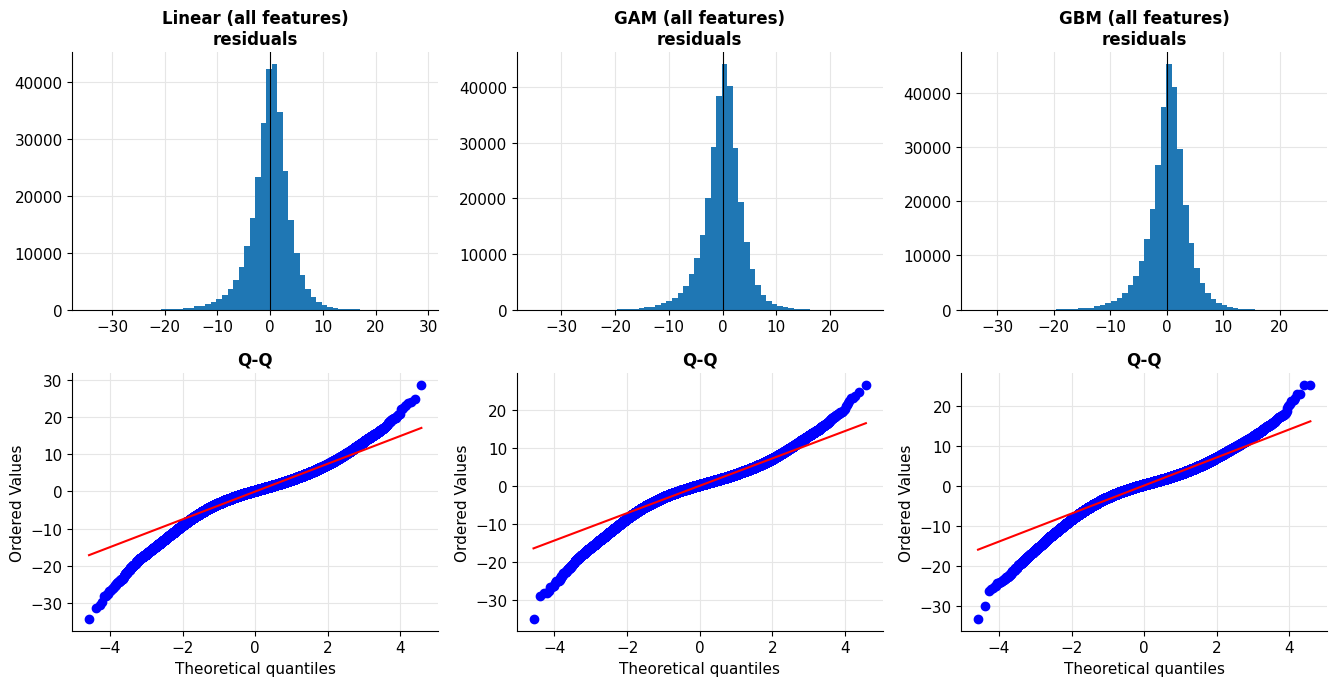

mean residual (bias) by NO2 level, ppb:
                       Linear (all features)  GAM (all features)  GBM (all features)
level                                                                              
[0.0, 10.0)                           2.720               2.590               2.340
[10.0, 15.0)                          1.200               1.170               1.310
[15.0, 20.0)                         -0.720              -0.610              -0.400
[20.0, 30.0)                         -3.680              -3.420              -3.130
[30.0, 1000000000.0)                 -8.550              -8.030              -7.350 



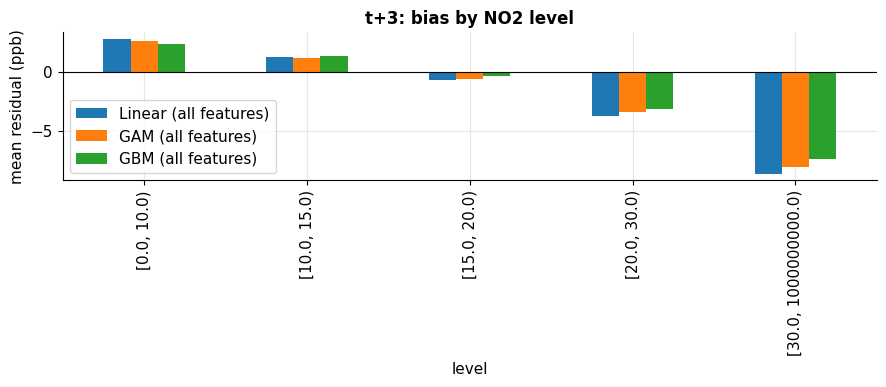

,MAE,RMSE,Bias,MASE,resid acf1 (median),% sensors acf1>0
model,,,,,,
Linear (all features),2.766,3.809,-0.038,0.903,0.657,100.000
GAM (all features),2.671,3.670,0.013,0.872,0.655,100.000
GBM (all features),2.604,3.589,0.154,0.850,0.647,100.000


In [58]:
h, va = 3, ROWS[3]["val"]
pick = ["Linear (all features)", "GAM (all features)", "GBM (all features)"]
residual_analysis(Y(h, va), {k: VAL_PRED[h][k] for k in pick},
                  NO2[va], SID[va], m["ts_utc"].to_numpy()[va], h)

# Forecast error diagnostics

We evaluate persistence, GAM, and GBM forecasts at 1-, 2-, and
3-hour horizons using validation predictions.

Objectives:
1. Identify systematic underprediction or overprediction.
2. Determine whether errors vary by hour, season, and concentration.
3. Examine remaining temporal dependence within sensors.
4. Compare model errors with persistence.
5. Identify large misses and location-specific failures.


In [59]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

H      = 3                                                  # horizon to diagnose
MODELS = ["Linear (all features)", "GAM (all features)", "GBM (all features)"]
PRED   = VAL_PRED                                           # final run: TEST_PRED
idx    = ROWS[H]["val"]                                     # final run: ROWS[H]["test"]

err = pd.DataFrame({"sid": SID[idx],
                    "ts":  pd.to_datetime(m["ts_utc"].to_numpy()[idx]),
                    "y":   Y(H, idx)})
for mn in MODELS:
    err[mn] = np.asarray(PRED[H][mn], float) - err["y"]     # error = predicted - observed
persist   = NO2[idx]                                        # persistence = value now
mae_naive = np.abs(persist - err["y"]).mean()
print(f"horizon t+{H} | rows {len(err):,} | models: {MODELS}")

horizon t+3 | rows 295,030 | models: ['Linear (all features)', 'GAM (all features)', 'GBM (all features)']


### Bias (mean forecast error)

The average signed error. It shows whether a model *systematically* leans high or low, as opposed to just being noisy. Near zero is good.


In [60]:
print((err[MODELS].mean()).rename("Bias: pred - obs (ppb)").round(3).to_string())


Linear (all features)   -0.038
GAM (all features)       0.013
GBM (all features)       0.154


Result (t+3, validation): bias is small for all models (Linear -0.04, GAM +0.01, GBM +0.15 ppb), so none has a serious overall lean. The important bias is conditional on pollution level

### Mean Absolute Error (MAE)

The average size of the errors in ppb, ignoring sign. This is the headline accuracy number because it is directly interpretable ("on average we miss by X ppb").


In [61]:
print((err[MODELS].abs().mean()).rename("MAE (ppb)").round(3).to_string())

Linear (all features)   2.766
GAM (all features)      2.671
GBM (all features)      2.604


Result (t+3, validation): Linear 2.77, GAM 2.67, GBM 2.60 ppb. GBM is the most accurate, with GAM close behind.

### Root Mean Squared Error (RMSE)

Like MAE but squares the errors first, so it **penalises large misses** much more heavily. RMSE sitting well above MAE signals occasional big errors.


In [62]:
print(((err[MODELS]**2).mean()**0.5).rename("RMSE (ppb)").round(3).to_string())

Linear (all features)   3.809
GAM (all features)      3.670
GBM (all features)      3.589


Result (t+3, validation): Linear 3.81, GAM 3.67, GBM 3.59 ppb. RMSE is well above MAE for every model, flagging occasional large misses - consistent with the under-prediction of high-NO2 peaks shown below.

### Mean Absolute Scaled Error (MASE)

MAE divided by the naive (persistence) forecast's MAE. Below 1 means the model beats "the value stays the same"; above 1 means it does not. It is scale-free, so it is comparable across horizons and pollutants.



In [63]:
print((err[MODELS].abs().mean() / mae_naive).rename("MASE (<1 beats naive)").round(3).to_string())

Linear (all features)   0.903
GAM (all features)      0.872
GBM (all features)      0.850


Result (t+3, validation): Linear 0.90, GAM 0.87, GBM 0.85 - all below 1, so every model beats the naive forecast, GBM by the most.

### Residual autocorrelation

Checks whether the forecast **errors** are still correlated from one hour to the next. If they are, the model left predictable temporal structure unused - a well-specified forecast should have near-white-noise errors. We measure each sensor's lag-1 error autocorrelation and summarise across sensors.



In [64]:
rows = []
for mn in MODELS:
    ac = (err.sort_values(["sid", "ts"]).groupby("sid")[mn]
             .apply(lambda s: s.autocorr(lag=1) if s.notna().sum() >= 10 else np.nan).dropna())
    rows.append({"model": mn, "resid acf1 (median)": ac.median(), "% sensors acf1>0": (ac > 0).mean()*100})
print(pd.DataFrame(rows).set_index("model").round(3).to_string())

                       resid acf1 (median)  % sensors acf1>0
model                                                       
Linear (all features)                0.657           100.000
GAM (all features)                   0.655           100.000
GBM (all features)                   0.647           100.000


Result (t+3, validation): the median lag-1 error autocorrelation is about 0.65 and positive at 100% of sensors. So the errors are not white noise - there is leftover persistence in them, a limitation that points to future work (e.g. modelling the error process).

### Error distribution (histogram and Q-Q)

The histogram and Q-Q plot show the *shape* of the errors. We want them centred on zero and roughly symmetric; heavy or skewed tails reveal occasional large misses that a single accuracy number hides.


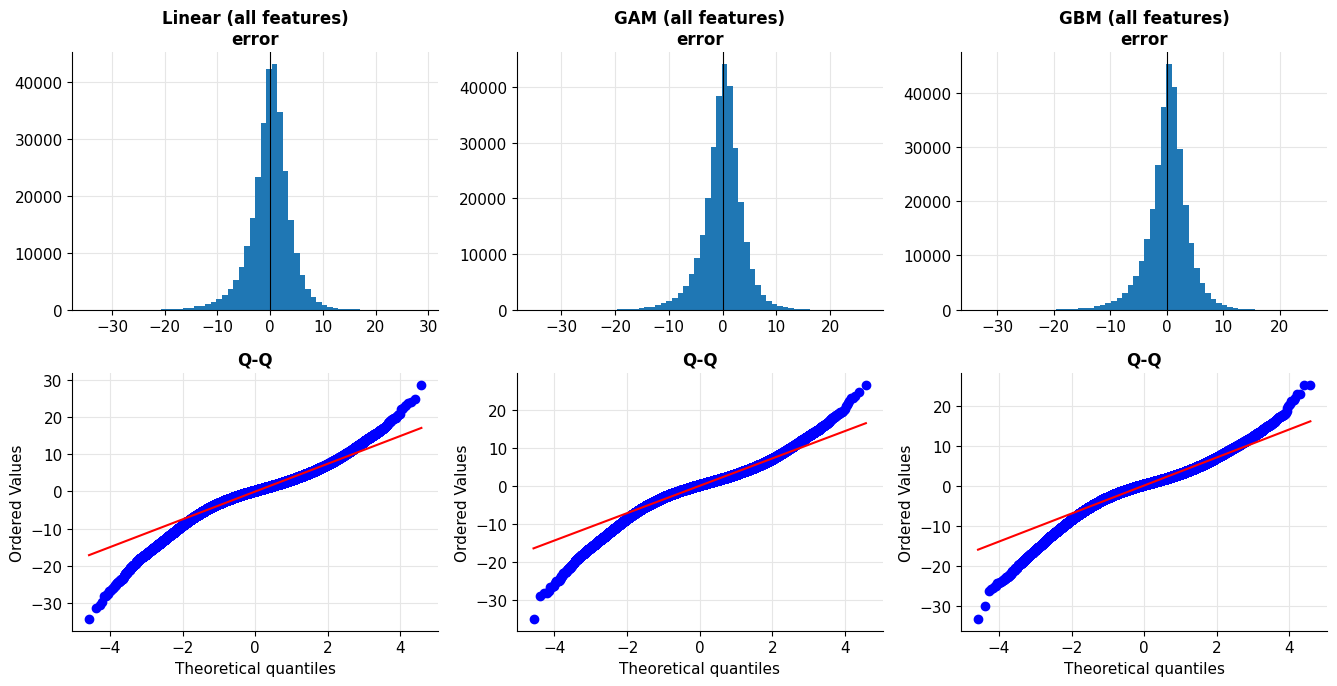

In [65]:
fig, ax = plt.subplots(2, len(MODELS), figsize=(4.5*len(MODELS), 7))
ax = np.atleast_2d(ax).reshape(2, len(MODELS))
for j, mn in enumerate(MODELS):
    e = err[mn].dropna().to_numpy()
    ax[0, j].hist(e, bins=60); ax[0, j].axvline(0, c="k", lw=.8); ax[0, j].set_title(f"{mn}\nerror")
    stats.probplot(e, plot=ax[1, j]); ax[1, j].set_title("Q-Q")
plt.tight_layout(); plt.show()

Result: the error distributions are centred near zero but have heavier tails than a normal distribution, confirming that most hours are forecast well while a minority - the pollution peaks - produce large errors.

### Bias by concentration level

Breaks the bias down by how polluted the hour actually was. This reveals where each model fails, which the overall bias hides.



mean error (pred - obs) by NO2 level, ppb:
        Linear (all features)  GAM (all features)  GBM (all features)
level                                                               
<10                    2.720               2.590               2.340
10-15                  1.200               1.170               1.310
15-20                 -0.720              -0.610              -0.400
20-30                 -3.680              -3.420              -3.130
30+                   -8.550              -8.030              -7.350


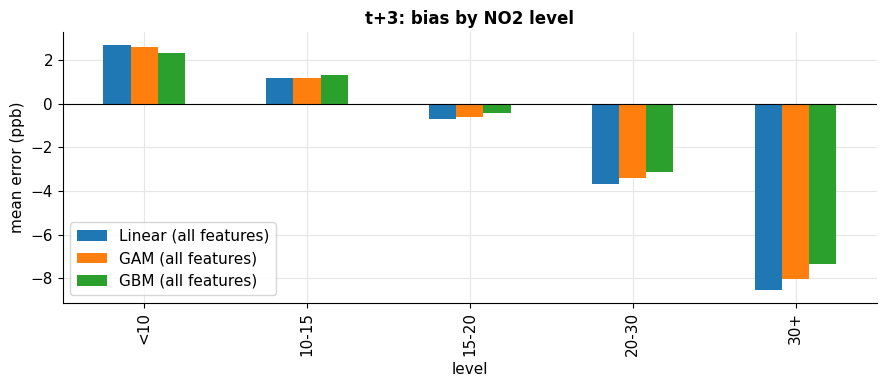

In [66]:
err["level"] = pd.cut(err["y"], [0, 10, 15, 20, 30, 1e9], right=False,
                      labels=["<10", "10-15", "15-20", "20-30", "30+"])
by = err.groupby("level", observed=True)[MODELS].mean()
print("mean error (pred - obs) by NO2 level, ppb:\n", by.round(2).to_string())
by.plot(kind="bar", figsize=(9, 4)); plt.axhline(0, c="k", lw=.8)
plt.ylabel("mean error (ppb)"); plt.title(f"t+{H}: bias by NO2 level"); plt.tight_layout(); plt.show()

Result (t+3, validation): every model over-predicts clean hours (<10 ppb: +2.3 to +2.7) and under-predicts dirty hours (30+ ppb: about -7 to -8.5). The models pull toward the average, so they systematically miss the high peaks - exactly the hours that matter most for an alert. This is the main weakness of the current forecasts; GBM is the least biased at the high end, so it handles extremes slightly better.

In [67]:
err["block"] = BLOCK[idx]        # week id per row, for clustered variance

### Diebold–Mariano test: is one model significantly more accurate?

The Diebold–Mariano (DM) test formally checks whether two forecasts have equal
accuracy, or whether one is genuinely better. It works on the **loss
differential** d = loss(model A) − loss(model B) for each observation (here,
absolute error). If the average of d is significantly different from zero, the
models differ in accuracy; **negative means the first model (GBM) has smaller
errors.**

Because our data is a panel (269 sensors × many hours) rather than one series,
we estimate the variance of the mean differential with **week-block clustering**,
so correlated errors within a week — across both time and sensors — do not make
the difference look more certain than it is. This matches the week-block
bootstrap already used elsewhere in the notebook.

**Understanding** a small p-value (e.g. < 0.05) means the accuracy difference
is really significant. a large p-value means the two models are statistically tied,
in which case we prefer the simpler one (GAM over GBM).

In [68]:
def dm_test(err, m1, m2, loss="abs"):
    """Loss differential d = loss(m1) - loss(m2); d<0 => m1 better. Week-block clustered variance."""
    g = (lambda e: np.abs(e)) if loss == "abs" else (lambda e: e**2)
    d  = g(err[m1].to_numpy()) - g(err[m2].to_numpy())
    N, dbar = len(d), d.mean()
    gsum = pd.Series(d - dbar).groupby(err["block"].to_numpy()).sum().to_numpy()  # cluster residual sums
    se   = np.sqrt((gsum**2).sum()) / N                                           # cluster-robust SE of the mean
    z    = dbar / se
    p    = 2 * stats.norm.sf(abs(z))
    return dbar, z, p, err["block"].nunique()

print(f"Diebold-Mariano (absolute-error loss), t+{H} — negative = first model better\n")
for m1, m2 in [("GBM (all features)", "GAM (all features)"),
               ("GBM (all features)", "Linear (all features)"),
               ("GAM (all features)", "Linear (all features)")]:
    dbar, z, p, G = dm_test(err, m1, m2)
    verdict = "significant" if p < 0.05 else "tied (not significant)"
    print(f"{m1:20s} vs {m2:22s}: mean|e| diff={dbar:+.4f}  z={z:+.2f}  p={p:.3g}  -> {verdict}  ({G} weeks)")

Diebold-Mariano (absolute-error loss), t+3 — negative = first model better

GBM (all features)   vs GAM (all features)    : mean|e| diff=-0.0670  z=-1.05  p=0.294  -> tied (not significant)  (8 weeks)
GBM (all features)   vs Linear (all features) : mean|e| diff=-0.1618  z=-2.28  p=0.0227  -> significant  (8 weeks)
GAM (all features)   vs Linear (all features) : mean|e| diff=-0.0949  z=-4.55  p=5.39e-06  -> significant  (8 weeks)




Both flexible models (GAM, GBM) significantly beat the linear model, so the nonlinearity is real, not noise. But GBM is not significantly more accurate than GAM (p = 0.29) - they are statistically tied. On Occam's razor idea  we therefore adopt the **GAM** as the primary model (simplest model tied with the best) and treat the GBM as an upper bound on achievable accuracy.

One further point -  GAM vs. Linear is *more* significant (z = -4.55) than GBM-vs-Linear (z = -2.28) despite GBM's larger raw gain, meaning the GAM beats the linear model reliably every week while GBM's edge is noisier - another reason to prefer the GAM.

Bonferroni (for multi test)